# Main file — 2026-06-04



In [1]:
include("packages.jl")
using DataFrames, CSV, Printf, Plots, Statistics, Dates

include("functions.jl")

🔧 Julia started with 12 threads


spindler_rts_comparison

In [5]:
# ============================================================================
# Isoacceptor-aware background-gene selector
#   Picks N_BG genes whose codons rest on ABUNDANT isoacceptors and avoid the
#   minority tRNA pools that crash the ODE at high N (Leu1-5, Ser5, His —
#   scale_tuning_log.md §5.2). Pure pre-screen: same source data the model uses
#   (AS_and_Codon.dat + FitCoefficients_eco_V9.xlsx::reltRNA). No scale changes.
# ============================================================================
using DataFrames, CSV, Printf, Statistics

# ---------- knobs ----------
SRC_FASTA      = "Ecoli_K12_MG1655_geneset_with_welch_2009.fa"  # file in data/sequences/
N_BG           = 30
PRIMARY_GENE   = "rplL"          # excluded from background, optionally written first
GROWTH_RATE    = 1.0             # µ (h⁻¹) — sets isoacceptor abundances
OUT_FASTA      = "../data/sequences/bg_safe_$(N_BG).fa"
REQUIRE_MRNA   = true            # keep only genes present in mRNA_concentrations.xlsx
INCLUDE_PRIMARY_IN_OUT = true
SLOW_PCTL      = 0.25            # codons below this supply-percentile = "slow"
SELECT_SAFEST  = true            # false = pick the WORST genes (stress test)
FRAGILE_NAMES  = ["Leu1","Leu2","Leu3","Leu4","Leu5","Ser5","His"]

# ---------- 1. isoacceptor abundance at GR (mirrors calculation_of_initial_concentration) ----------
fit  = "../data/input/FitCoefficients_eco_V9.xlsx"
tm   = Float64.(readmatrix(fit, "Translation_machinery", "B2:D14"))
S50  = tm[2,3] + tm[2,1]*GROWTH_RATE/(tm[2,2]+GROWTH_RATE)          # 50S µM at µ
rel  = Float64.(readmatrix(fit, "reltRNA", "B2:D40"))               # 39 rows: [initiator; 38 elongators]
tRNAconc    = (rel[:,1].*exp.(-rel[:,2].*GROWTH_RATE) .+ rel[:,3]) .* S50
elong_abund = tRNAconc[2:39]                                        # row 1 = initiator (b1t) -> drop

# ---------- 2. codon -> cognate isoacceptor rows & total supply (AS_and_Codon.dat) ----------
ascod    = DataFrame(CSV.File("../data/input/AS_and_Codon.dat", delim=';', missingstring=""))
iso_name = String.(strip.(ascod.tRNAas))
codon_supply = Dict{String,Float64}()
codon_isos   = Dict{String,Vector{Int}}()
for (t, codstr) in enumerate(ascod.codAS)
    for c in split(String(codstr), ",")
        cc = strip(c); isempty(cc) && continue
        codon_supply[cc] = get(codon_supply, cc, 0.0) + elong_abund[t]
        push!(get!(codon_isos, cc, Int[]), t)
    end
end
FRAGILE  = Set(filter(!isnothing, [findfirst(==(n), iso_name) for n in FRAGILE_NAMES]))
slow_cut = quantile(collect(values(codon_supply)), SLOW_PCTL)

println(@sprintf("S50(µ=%.2f) = %.2f µM   |   slow-codon cutoff (p%d) = %.3f µM",
        GROWTH_RATE, S50, round(Int,100*SLOW_PCTL), slow_cut))
println("10 scarcest codons (codon => total cognate supply µM):")
for (c,s) in sort(collect(codon_supply), by=x->x[2])[1:10]
    println(@sprintf("   %-4s %.3f   [%s]", c, s, join(iso_name[codon_isos[c]], ",")))
end

# ---------- 3. load candidate sequences ----------
nrec = length(readfasta(joinpath("..","data","sequences", SRC_FASTA)))
seqs_all, names_all = seqs_import_transcripts(SRC_FASTA, (1, nrec))

candidates = String[g for g in names_all if g != PRIMARY_GENE]
if REQUIRE_MRNA
    mrna_df    = to_DataFrame(readmatrix("../data/input/mRNA_concentrations.xlsx",
                                         "mRNA_concentration", "A1:B2324"))
    mrna_genes = Set(String.(strip.(mrna_df.gene)))
    candidates = filter(g -> g in mrna_genes, candidates)
end

# ---------- 4. score each candidate ----------
rows = NamedTuple[]
for g in candidates
    haskey(seqs_all, g) || continue
    codons = String.(seqs_all[g].Codon)
    length(codons) < 2 && continue
    sup = Float64[]; nfrag = 0
    for c in codons[1:end-1]                              # drop terminal (stop) codon
        haskey(codon_supply, c) || continue              # skip stops / unknowns
        push!(sup, codon_supply[c])
        isempty(intersect(Set(codon_isos[c]), FRAGILE)) || (nfrag += 1)
    end
    isempty(sup) && continue
    push!(rows, (gene=g, L=length(sup),
                 harm_supply = length(sup)/sum(1.0 ./ sup),   # usage-weighted; dominated by scarce codons
                 min_supply  = minimum(sup),
                 frac_slow   = count(<=(slow_cut), sup)/length(sup),
                 frac_fragile= nfrag/length(sup)))
end
df = DataFrame(rows)
sort!(df, :harm_supply, rev = SELECT_SAFEST)              # safest (high harmonic supply) first
selected_bg = df.gene[1:min(N_BG, nrow(df))]

# ---------- 5. report + write FASTA ----------
println("\nSelected $(length(selected_bg)) background genes ($(SELECT_SAFEST ? "SAFEST" : "WORST")):")
show(first(df, length(selected_bg)), allrows=true, allcols=true); println()

open(OUT_FASTA, "w") do io
    if INCLUDE_PRIMARY_IN_OUT && haskey(seqs_all, PRIMARY_GENE)
        println(io, ">", PRIMARY_GENE); println(io, String(seqs_all[PRIMARY_GENE].DNA))
    end
    for g in selected_bg
        println(io, ">", g); println(io, String(seqs_all[g].DNA))
    end
end
println("\nWrote → ", OUT_FASTA, "   |   use `selected_bg` directly as your background list.")

S50(µ=1.00) = 20.09 µM   |   slow-codon cutoff (p25) = 2.635 µM
10 scarcest codons (codon => total cognate supply µM):
   AGG  1.209   [Arg5]
   CCA  1.478   [Pro3]
   CGG  1.534   [Arg3]
   GCC  1.734   [Ala2]
   CAC  1.844   [His]
   CAU  1.844   [His]
   CCC  1.899   [Pro2]
   CUA  1.922   [Leu3]
   AGA  1.928   [Arg4]
   UCC  2.012   [Ser5]

Selected 30 background genes (SAFEST):
30×6 DataFrame
 Row │ gene    L      harm_supply  min_supply  frac_slow  frac_fragile 
     │ String  Int64  Float64      Float64     Float64    Float64      
─────┼─────────────────────────────────────────────────────────────────
   1 │ rplO      144      6.40101     1.73385  0.0763889     0.138889
   2 │ rpsU       71      6.36457     1.84391  0.0422535     0.0985915
   3 │ rplI      149      6.13841     1.47812  0.0604027     0.107383
   4 │ mopB       97      6.13717     1.47812  0.0618557     0.134021
   5 │ tig       432      6.02168     1.47812  0.0787037     0.0925926
   6 │ hupB       90      5.96

🔧 Julia started with 12 threads
Candidate pool: 20 genes (in FASTA ∩ mRNA-xlsx, excluding rplL)

──────────────────────────────────────────────────────────────────────────────
  Background selection mode = :first   N_current = 20
──────────────────────────────────────────────────────────────────────────────
First 20 genes in mRNA-xlsx order:
  tufA, acpP, rplO, rplJ, rplA, rpsA, mopB, rpsP, rpsI, eno, tsf, rpsU, pgk, hupB, tig, rplT, mopA, rplI, frr, greA

Pre-flight:
  n_seq          = 21  (1 primary + 20 background)
  m_rplL         = 1.3156 µM   |   m_bg_each = 0.0772 µM   |   total_mRNA = 2.8600 µM
  gene-block states ≈ 4960  (+ ~340 shared metabolites)   |   timeout = 36000 s

══════════════════════════════════════════════════════════════════════════════
  Solving ODE for N_current = 20 …
══════════════════════════════════════════════════════════════════════════════


Number of sequences: 21 (background_selection=first)

========== EF pool audit (literature bands: Tu/Rib ~5–9×, Ts/Rib ~1×, Tu/Ts ~5–9×, EF-G/Rib ~1.5–2.5×) ==========
  Eut (total EF-Tu, constant_vars[13])     = 224.14529514482248 µM
  Est (EF-Ts, constant_vars[14])          = 19.45182200314482 µM
  S50 (50S subunit, state after balance)  = 20.08605675055541 µM
  c_EFG_t (DAE total EF-G, parameters.jl) = 39.56753084105652 µM
  EFG+EGT+EGD (state after EF_balance!)   = 39.56753084105652 µM  (should ≈ c_EFG_t)
  Eut/S50      = 11.159248324767603   [~5–9]
  Est/S50      = 0.9684241284744427   [~~1]
  Eut/Est      = 11.523100258093274   [~5–9]
  c_EFG_t/S50  = 1.9699003807684856   [~1.5–2.5]
========== end EF pool audit ==========

  Solver: FBDF  rtol=1.0e-8  atol=1.0e-5  maxiters=5000000  (n_seq=21)
Integration completed!

  Wall time: 17845.7 s   →   task_status = ok

  rplL total time = 560.3762 s   |   mean v = 13.5154 codons/s   |   L = 120   |   state_size = 5072
  Mean T3 = 3.8721

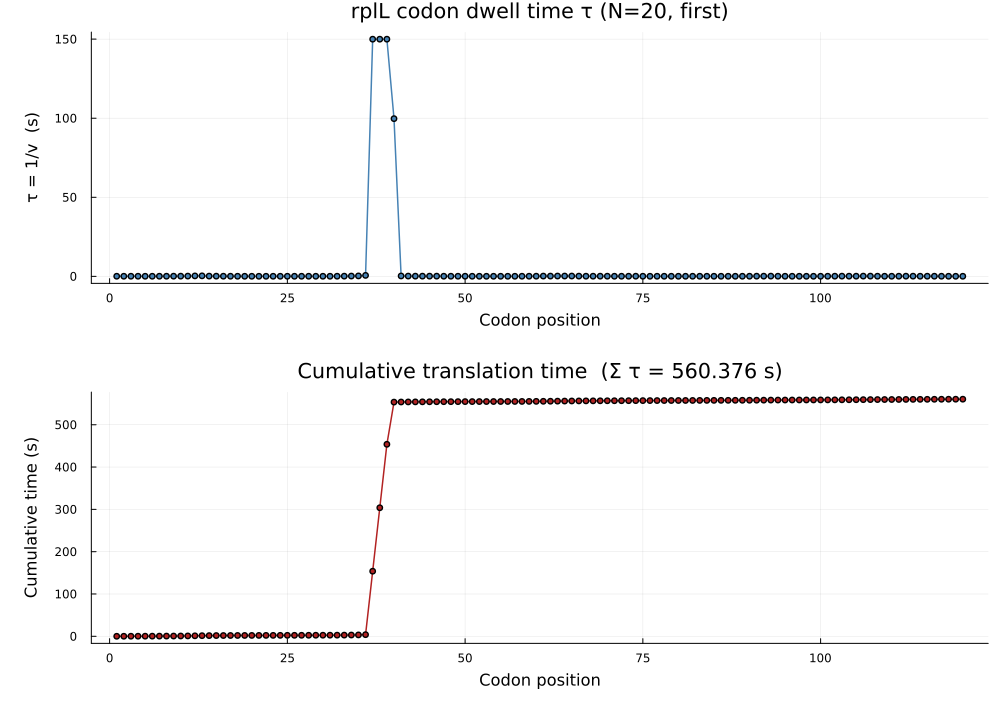

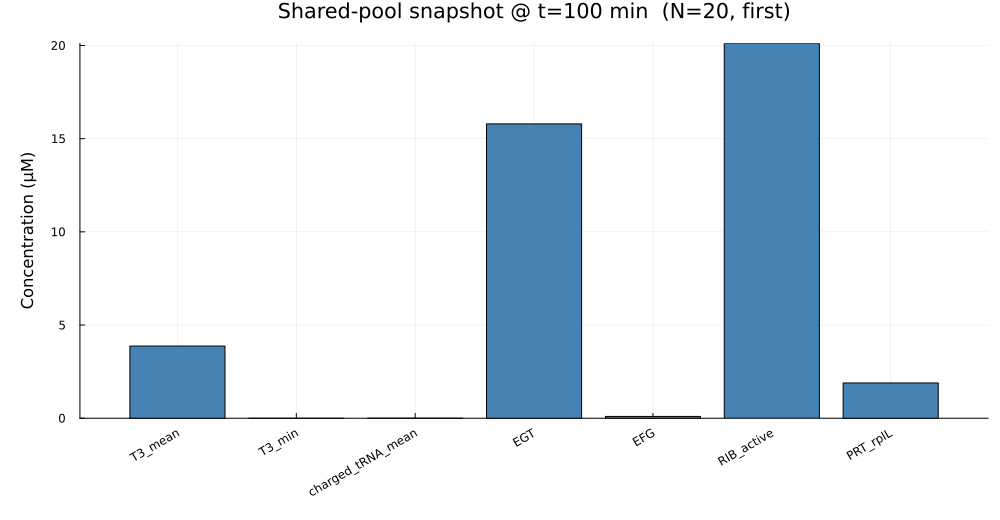

In [5]:
# ═══════════════════════════════════════════════════════════════════════════════
# E. coli Reference Genome — single-N background runner for rplL
#
#   Why "single-N" and not a sweep:
#   The 2026-05-19 N-sweep on the alphabetic-ordered (:first) background pool
#   produced a non-monotonic rplL_total_time(N) curve (N=1: 11 s, N=3: 521 s,
#   N=5: 7.9 s, N=10: 557 s). Diagnosis (T3_min ≈ 0 at N=3, N=10): single-codon
#   stalls driven by which tRNA the *composition* of the first-N alphabetic
#   genes happens to clobber. total_time = Σ 1/v_i is pseudo-harmonic and
#   blows up on any single stalled codon, while mean_v (arithmetic) does not.
#   So the :first rule is a codon-mix LOTTERY.
#
#   Fix: pick the N background genes that make the union (rplL + background)
#   amino-acid usage as close as possible to the proteome average (greedy L1
#   minimisation against the 20-aa average from the full FASTA). This holds
#   codon mix ~constant across N so the only remaining variable is
#   number-of-competitors-for-a-fixed-mRNA-budget — the actual research
#   question.
#
#   Workflow:
#     - Set N_current ∈ {20, 30, 40, 50} once.
#     - All outputs are tagged with N: data/output/spindler_rplL_N{N}_{mode}_*.csv
#       and data/output/figures/spindler_rplL_N{N}_{mode}_*.png.
#     - The cell calls ode_bottleneck_report(...) after the run to surface
#       which ODE state (and which codon position on rplL) is the local
#       bottleneck. See CHANGELOG 2026-05-20.
# ═══════════════════════════════════════════════════════════════════════════════
include("packages.jl")
using DataFrames, CSV, Printf, Plots, Statistics, Dates

include("functions.jl")

# ─── User-facing knobs ─────────────────────────────────────────────────────────
N_current         = 20                       # ← set to 10, 20, 30, 40, 50 and re-run; all outputs are tagged per N
bg_selection_mode = :first                   # :first reproduces the canonical spindler_rplL_N*_first_* runs | :codon_balanced also available
m_total           = 2.86                      # µM, total mRNA budget (matches rplL+3-RTS cell)
f_rplL            = 0.46 # 0.3 Old                     # rplL share of the budget
t_sample          = 100.0                    # min, ODE snapshot time
primary_gene      = "rplL"
fasta_filename    = "bg_safe_20.fa"  # under data/sequences/
timeout_run_sec   = 600 * 60                 # 3 h cap for the 100-min run at run-I scales (see runs_summary.md)
ode_reltol_run    = 1e-8
# atol U-shaped ladder (runs_summary.md): N<=10 -> 1e-4, 15<=N<=45 -> 1e-5, N>=50 -> 1e-4
ode_abstol_run    =  1e-5 #(N_current <= 10 || N_current >= 50) ? 1e-4 #<--- change for N=50
ode_maxiters_run  = 5_000_000
ode_bottleneck_topk = 15                     # top-k states printed by ode_bottleneck_report

# Spindler-faithful scaling factors (match spindler_rts_comparison)
spindler_scale = txtl_types.make_scale(
    V_IN_70SIC_scale = 75.0,
    V_IN_IF2D_scale  = 2.0,
    ARS_scale        = 20.0 .* ones(20),
    Rib_scale        = 1.0,
    EF_scale         = 1, #sqrt(2.0),
    tRNA_scale       = 1, #1.7,
)

# ─── Load FASTA and mRNA pool (candidate set construction) ─────────────────────
seqs_to_use_pool = (1, 2401)
mRNA_pool = to_DataFrame(readmatrix("../data/input/mRNA_concentrations.xlsx",
                                    "mRNA_concentration", "A1:B2402"))
mRNA_pool = filter(row -> isa(row.mRNA, Number), mRNA_pool)

seqs_all_fasta, _ = seqs_import_transcripts(fasta_filename, seqs_to_use_pool)
fasta_gene_set    = Set{String}(String.(keys(seqs_all_fasta)))

# Build the candidate set: genes present in BOTH the mRNA xlsx and the FASTA,
# excluding the primary gene. The xlsx order is used as a stable "all genes"
# iteration order; the selection algorithm chooses from this candidate pool.
candidate_pool = String[]
for i in 1:nrow(mRNA_pool)
    g = String(mRNA_pool.gene[i])
    g == primary_gene && continue
    g in fasta_gene_set || continue
    push!(candidate_pool, g)
end
@printf("Candidate pool: %d genes (in FASTA ∩ mRNA-xlsx, excluding %s)\n",
        length(candidate_pool), primary_gene)

# ─── Select N_current background genes by chosen mode ──────────────────────────
println("\n" * "─"^78)
println("  Background selection mode = :$(bg_selection_mode)   N_current = $N_current")
println("─"^78)

local_bg_list   = String[]
balance_summary = nothing   # for :codon_balanced this holds the NamedTuple result

if bg_selection_mode == :first
    local_bg_list = candidate_pool[1:min(N_current, length(candidate_pool))]
    println("First $(length(local_bg_list)) genes in mRNA-xlsx order:")
    println("  ", join(local_bg_list, ", "))

elseif bg_selection_mode == :codon_balanced
    println("Computing proteome-average aa fractions across all $(length(seqs_all_fasta)) FASTA genes…")
    balance_summary = codon_balanced_background_selection(
        seqs_all_fasta, candidate_pool, primary_gene, N_current;
        seed_with_primary = true, verbose = true)
    local_bg_list = balance_summary.selected

    println("\nFinal codon-balance audit (primary + $(length(local_bg_list)) background):")
    @printf("  L1 deviation from proteome avg = %.4f\n", balance_summary.final_dev_l1)
    @printf("  Max per-aa deviation           = %.2f%%  (X-percent tolerance metric)\n",
            balance_summary.final_dev_pct_max)
    println("  Per-aa fractions (selected vs proteome target):")
    @printf("    %-3s  %12s  %12s  %12s\n", "aa", "selected", "target", "Δ%")
    for k in 1:20
        sel = balance_summary.final_fractions[k]
        tgt = balance_summary.target[k]
        delta_pct = tgt > 0 ? 100.0 * (sel - tgt) / tgt : NaN
        @printf("    %-3s  %12.4f  %12.4f  %12.2f\n",
                string(AA20_LETTERS[k]), sel, tgt, delta_pct)
    end
else
    error("Unknown bg_selection_mode = $bg_selection_mode  (expected :first or :codon_balanced)")
end

# ─── Build heterologous block ──────────────────────────────────────────────────
m_rplL = m_total * f_rplL
m_bg   = N_current == 0 ? 0.0 : m_total * (1 - f_rplL) / N_current
het_genes = vcat([primary_gene], local_bg_list)
het_conc  = Dict{String,Float64}(primary_gene => m_rplL)
for g in local_bg_list
    het_conc[g] = m_bg
end

# Pre-flight diagnostic — state-vector size estimate.
bg_codon_lens = [haskey(seqs_all_fasta, g) ? length(seqs_all_fasta[g].Codon) : 0
                 for g in het_genes]
est_codon_states = sum(4 .+ bg_codon_lens)
total_mRNA       = m_rplL + N_current * m_bg
println("\nPre-flight:")
@printf("  n_seq          = %d  (1 primary + %d background)\n",
        length(het_genes), length(local_bg_list))
@printf("  m_rplL         = %.4f µM   |   m_bg_each = %.4f µM   |   total_mRNA = %.4f µM\n",
        m_rplL, m_bg, total_mRNA)
@printf("  gene-block states ≈ %d  (+ ~340 shared metabolites)   |   timeout = %.0f s\n",
        est_codon_states, Float64(timeout_run_sec))
flush(stdout)

# ─── L3 helper: wall-time-bounded call (carried over from sweep cell) ──────────
function _run_with_timeout(f, timeout_s::Real)
    ch = Channel{Any}(1)
    t_task = @async try
        put!(ch, (:ok, f()))
    catch e
        put!(ch, (:error, e))
    end
    t0 = time()
    while !istaskdone(t_task)
        if time() - t0 > timeout_s
            return (:timeout, nothing, time() - t0)
        end
        sleep(0.5)
    end
    elapsed = time() - t0
    status, payload = take!(ch)
    return (status, payload, elapsed)
end

# ─── Run the single integration (Tier-1 settings: static_EFs=true, 75pct=false) ─
println("\n" * "═"^78)
println("  Solving ODE for N_current = $N_current …")
println("═"^78)
mkpath("../data/output")
mkpath("../data/output/figures")

status, payload, elapsed = _run_with_timeout(timeout_run_sec) do
    call_model(fasta_filename, het_genes, 0;
        custom_scale   = spindler_scale,
        growth_rate    = 1,
        het_mRNA_conc  = het_conc,
        return_details = true,
        return_sol     = true,
        static_EFs     = true,
        spindler_75pct = false,
        ode_reltol     = ode_reltol_run,
        ode_abstol     = ode_abstol_run,
        ode_maxiters   = ode_maxiters_run)
end
@printf("\n  Wall time: %.1f s   →   task_status = %s\n", elapsed, status)
flush(stdout)

# ─── Status detection (mirrors the Tier-1 logic from the sweep cell) ───────────
effective_status  = "ok"
sol_t_end_min     = NaN
retcode_str       = "n/a"
eval_t_min        = t_sample
actual_state_size = est_codon_states
res               = nothing

if status == :error
    @warn "call_model threw" exception = payload
    effective_status = "error"
elseif status == :timeout
    @warn "call_model exceeded timeout_run_sec" timeout_s = timeout_run_sec elapsed_s = round(elapsed, digits=1)
    effective_status = "timeout"
else
    res = payload
    actual_state_size = length(res.sol.u[end])
    sol_t_end_min     = float(res.sol.t[end])
    retcode_str       = string(res.sol.retcode)
    if !successful_retcode(res.sol)
        effective_status = "solver_failed"
        @warn "Solver returned non-success retcode" retcode = retcode_str sol_t_end_min = sol_t_end_min
    elseif sol_t_end_min < t_sample - 1e-9
        effective_status = "incomplete"
        @warn "Solver succeeded but stopped before t_sample" sol_t_end_min = sol_t_end_min t_sample = t_sample
    end
    eval_t_min = min(t_sample, sol_t_end_min)
end

# ─── Evaluate metrics + bottleneck report (if any integrated time was reached) ─
sp   = nothing
diag = nothing

if res !== nothing && eval_t_min > res.sol.t[1]
    sp   = spindler_codon_translation_time(res.sol, res.p, primary_gene;
                                           t_sample = eval_t_min)
    diag = collect_pool_diagnostics(res.sol, res.p, eval_t_min;
                                    primary_gene = primary_gene)

    @printf("\n  rplL total time = %.4f s   |   mean v = %.4f codons/s   |   L = %d   |   state_size = %d\n",
            sp.total_time_s, sp.mean_v, sp.L, actual_state_size)
    @printf("  Mean T3 = %.4f µM   |   T3_min = %.4e µM   |   KM/T3 = %.4f   |   charged tRNA = %.4f µM\n",
            diag.T3_mean, diag.T3_min, diag.mean_sat, diag.charged_mean)
    @printf("  EGT = %.2f µM   |   EFG = %.2f µM   |   RIB_active = %.4f µM   |   PRT(rplL) = %.4f µM\n",
            diag.EGT, diag.EFG, diag.RIB_active, diag.PRT_primary)
    @printf("  Effective status: %s   |   eval_t = %.3f min   |   sol_t_end = %.3f min   |   retcode = %s\n",
            effective_status, eval_t_min, sol_t_end_min, retcode_str)

    # The actionable "which ODE/codon is the bottleneck?" report.
    ode_bottleneck_report(res, eval_t_min;
        primary_gene = primary_gene,
        top_k = ode_bottleneck_topk)
else
    @warn "No integrated time available — skipping metrics and bottleneck report" eval_t_min sol_t_end_min effective_status
end

# ─── Persist per-N outputs (tagged so 20/30/40/50 runs accumulate) ─────────────
mode_tag = string(bg_selection_mode)
tag      = "N$(N_current)_$(mode_tag)"

summary_row = (
    N                = N_current,
    selection_mode   = mode_tag,
    n_seq            = length(het_genes),
    status           = effective_status,
    ok               = effective_status == "ok",
    wall_time_s      = elapsed,
    est_codon_states = actual_state_size,
    m_rplL           = m_rplL,
    m_bg_each        = m_bg,
    total_mRNA       = total_mRNA,
    eval_t_min       = eval_t_min,
    sol_t_end_min    = sol_t_end_min,
    retcode          = retcode_str,
    rplL_total_time_s = sp === nothing ? NaN : sp.total_time_s,
    rplL_mean_v       = sp === nothing ? NaN : sp.mean_v,
    rplL_L            = sp === nothing ? 0   : sp.L,
    T3_mean           = diag === nothing ? NaN : diag.T3_mean,
    T3_min            = diag === nothing ? NaN : diag.T3_min,
    T3_max            = diag === nothing ? NaN : diag.T3_max,
    charged_tRNA_mean = diag === nothing ? NaN : diag.charged_mean,
    EGT               = diag === nothing ? NaN : diag.EGT,
    EFG               = diag === nothing ? NaN : diag.EFG,
    KM_T3j            = diag === nothing ? NaN : diag.KM_T3j,
    mean_sat          = diag === nothing ? NaN : diag.mean_sat,
    RIB_active        = diag === nothing ? NaN : diag.RIB_active,
    PRT_primary       = diag === nothing ? NaN : diag.PRT_primary,
    final_PRT         = res === nothing ? NaN : res.final_PRT,
    aa_balance_L1     = balance_summary === nothing ? NaN : balance_summary.final_dev_l1,
    aa_balance_pct_max = balance_summary === nothing ? NaN : balance_summary.final_dev_pct_max,
)
CSV.write("../data/output/spindler_rplL_$(tag)_summary.csv", DataFrame([summary_row]))

# Per-codon detail — same schema as the sweep cell, with an N column.
codon_rows = NamedTuple[]
if sp !== nothing
    cum = cumsum(sp.tau)
    for (j, t_cum) in enumerate(cum)
        push!(codon_rows, (N = N_current, codon = j, cum_time_s = t_cum,
                            tau_s = sp.tau[j], v_codons_s = sp.v_smooth[j]))
    end
end
CSV.write("../data/output/spindler_rplL_$(tag)_codon_detail.csv", DataFrame(codon_rows))

# ─── Cross-run elongation log (per-codon rows, appendable) ──────────────────
# One row per rplL codon, carrying run-level params so plot_cross_N.py can filter
# by (timestamp, N). Schema matches the existing elongation_rate_log.csv. Only
# :ok runs with a usable sp are appended.
elong_log_path = "../data/output/elongation_rate_log.csv"
run_ts = string(Dates.now())
if sp !== nothing && effective_status == "ok"
    cumE = cumsum(sp.tau)
    elong_rows = NamedTuple[]
    for j in 1:sp.L
        push!(elong_rows, (
            timestamp         = run_ts,
            N                 = N_current,
            n_seq             = length(het_genes),
            bg_mode           = mode_tag,
            primary_gene      = primary_gene,
            codon_pos         = j,
            tau_s             = sp.tau[j],
            v_smooth_cod_s    = sp.v_smooth[j],
            cum_time_s        = cumE[j],
            rplL_total_time_s = sp.total_time_s,
            rplL_mean_v_cs    = sp.mean_v,
            T3_min            = diag === nothing ? NaN : diag.T3_min,
            T3_mean           = diag === nothing ? NaN : diag.T3_mean,
            m_rplL            = m_rplL,
            m_bg_each         = m_bg,
            total_mRNA        = total_mRNA,
            V_IN_70SIC_scale  = spindler_scale.V_IN_70SIC_scale,
            V_IN_IF2D_scale   = spindler_scale.V_IN_IF2D_scale,
            ARS_scale         = first(spindler_scale.ARS_scale),
            tRNA_scale        = spindler_scale.tRNA_scale,
            EF_scale          = spindler_scale.EF_scale,
            Rib_scale         = spindler_scale.Rib_scale,
            ode_reltol        = ode_reltol_run,
            ode_abstol        = ode_abstol_run,
            t_sample_min      = t_sample,
            sol_t_end_min     = sol_t_end_min,
            wall_time_s       = elapsed,
        ))
    end
    let elong_exists = isfile(elong_log_path)
        CSV.write(elong_log_path, DataFrame(elong_rows);
                  append = elong_exists, writeheader = !elong_exists)
    end
    @printf("  Appended %d codon rows  →  %s\n", length(elong_rows), elong_log_path)
else
    @info "Elongation log NOT appended" reason = (sp === nothing ? "no sp (integration did not produce a usable sol)" : "effective_status=$(effective_status) — only :ok runs are logged")
end

# ─── Run-level summary log (cross-run, appendable) ──────────────────────────────
# One row per run with all params + key results + the 3 most-depleted T3 species
# at eval_t. Use this CSV for cross-N "limiting tRNA" plots, Στ vs N scatter,
# pool-stability vs N — anything where you want exactly one number per run.
run_summary_log_path = "../data/output/run_summary_log.csv"

# Extract the 3 most-depleted T3 (charged tRNA·EF-Tu·GTP) species at eval_t.
# Names: tags.species_and_sequences.Tag[idx.a1t:idx.y1t] (e.g. "a1t", "e2t", ...).
limiting_T3_name = ""
limiting_T3_uM   = NaN
second_T3_name   = ""
second_T3_uM     = NaN
third_T3_name    = ""
third_T3_uM      = NaN
if res !== nothing && eval_t_min > res.sol.t[1]
    try
        tags_run     = res.p.local_tags_list[1]
        t3_range     = tags_run.idx.a1t : tags_run.idx.y1t
        t3_names_run = String.(tags_run.species_and_sequences.Tag[t3_range])
        t3_vals_run  = Float64.(res.sol(eval_t_min)[t3_range])
        ord          = sortperm(t3_vals_run)   # ascending → most depleted first
        length(ord) >= 1 && (limiting_T3_name = t3_names_run[ord[1]]; limiting_T3_uM = t3_vals_run[ord[1]])
        length(ord) >= 2 && (second_T3_name   = t3_names_run[ord[2]]; second_T3_uM   = t3_vals_run[ord[2]])
        length(ord) >= 3 && (third_T3_name    = t3_names_run[ord[3]]; third_T3_uM    = t3_vals_run[ord[3]])
    catch e
        @warn "Failed to extract limiting T3 species" exception = e
    end
end

run_summary_row = (
    timestamp         = string(Dates.now()),
    N                 = N_current,
    bg_mode           = mode_tag,
    primary_gene      = primary_gene,
    status            = effective_status,
    wall_time_s       = elapsed,
    eval_t_min        = eval_t_min,
    sol_t_end_min     = sol_t_end_min,
    t_sample_min      = t_sample,
    rplL_total_time_s = sp === nothing ? NaN : sp.total_time_s,
    rplL_mean_v_cs    = sp === nothing ? NaN : sp.mean_v,
    rplL_L            = sp === nothing ? 0   : sp.L,
    T3_mean           = diag === nothing ? NaN : diag.T3_mean,
    T3_min            = diag === nothing ? NaN : diag.T3_min,
    T3_max            = diag === nothing ? NaN : diag.T3_max,
    charged_tRNA_mean = diag === nothing ? NaN : diag.charged_mean,
    EGT               = diag === nothing ? NaN : diag.EGT,
    EFG               = diag === nothing ? NaN : diag.EFG,
    RIB_active        = diag === nothing ? NaN : diag.RIB_active,
    PRT_rplL          = diag === nothing ? NaN : diag.PRT_primary,
    limiting_T3_name  = limiting_T3_name,
    limiting_T3_uM    = limiting_T3_uM,
    second_T3_name    = second_T3_name,
    second_T3_uM      = second_T3_uM,
    third_T3_name     = third_T3_name,
    third_T3_uM       = third_T3_uM,
    m_rplL            = m_rplL,
    m_bg_each         = m_bg,
    total_mRNA        = total_mRNA,
    n_seq             = length(het_genes),
    V_IN_70SIC_scale  = spindler_scale.V_IN_70SIC_scale,
    V_IN_IF2D_scale   = spindler_scale.V_IN_IF2D_scale,
    ARS_scale         = first(spindler_scale.ARS_scale),
    tRNA_scale        = spindler_scale.tRNA_scale,
    EF_scale          = spindler_scale.EF_scale,
    Rib_scale         = spindler_scale.Rib_scale,
    ode_reltol        = ode_reltol_run,
    ode_abstol        = ode_abstol_run,
)
let summary_file_exists = isfile(run_summary_log_path)
    CSV.write(run_summary_log_path, DataFrame([run_summary_row]);
              append = summary_file_exists, writeheader = !summary_file_exists)
end
@printf("  Appended run summary    →  %s\n", run_summary_log_path)
@printf("  Limiting tRNA at t=%.0f min: %s = %.4e µM   (2nd: %s = %.4e,  3rd: %s = %.4e)\n",
        eval_t_min, limiting_T3_name, limiting_T3_uM,
        second_T3_name, second_T3_uM, third_T3_name, third_T3_uM)

# Background-gene audit + per-aa balance (only meaningful for :codon_balanced).
bg_rows = NamedTuple[]
for (rank, g) in enumerate(local_bg_list)
    push!(bg_rows, (N = N_current, rank = rank, gene = g, mRNA_uM = m_bg))
end
CSV.write("../data/output/spindler_rplL_$(tag)_background_genes.csv", DataFrame(bg_rows))

if balance_summary !== nothing
    aa_rows = NamedTuple[]
    for k in 1:20
        sel = balance_summary.final_fractions[k]
        tgt = balance_summary.target[k]
        push!(aa_rows, (
            aa            = string(AA20_LETTERS[k]),
            selected_frac = sel,
            target_frac   = tgt,
            abs_delta     = abs(sel - tgt),
            pct_delta     = tgt > 0 ? 100.0 * (sel - tgt) / tgt : NaN))
    end
    CSV.write("../data/output/spindler_rplL_$(tag)_aa_balance.csv", DataFrame(aa_rows))
end

# ─── Plots (tagged with N so each run produces fresh files) ────────────────────
if sp !== nothing
    # Plot 1: rplL codon profile — τ (s) and cumulative time vs codon position.
    p_tau = plot(1:sp.L, sp.tau;
        marker = :circle, markersize = 3, linewidth = 1.5, color = :steelblue,
        xlabel = "Codon position", ylabel = "τ = 1/v  (s)",
        title  = @sprintf("%s codon dwell time τ (N=%d, %s)", primary_gene, N_current, mode_tag),
        legend = false,
        left_margin = 8Plots.mm, bottom_margin = 8Plots.mm)
    cum = cumsum(sp.tau)
    p_cum = plot(1:length(cum), cum;
        marker = :circle, markersize = 3, linewidth = 1.5, color = :firebrick,
        xlabel = "Codon position", ylabel = "Cumulative time (s)",
        title  = @sprintf("Cumulative translation time  (Σ τ = %.3f s)", sp.total_time_s),
        legend = false,
        left_margin = 8Plots.mm, bottom_margin = 8Plots.mm)
    p_profile = plot(p_tau, p_cum; layout = (2, 1), size = (1000, 720))
    savefig(p_profile, "../data/output/figures/spindler_rplL_$(tag)_codon_profile.png")
    display(p_profile)
end

if diag !== nothing
    # Plot 2: pool snapshot bar chart — single-run summary, comparable across N.
    pool_names = ["T3_mean", "T3_min", "charged_tRNA_mean", "EGT", "EFG",
                  "RIB_active", "PRT_rplL"]
    pool_vals  = [diag.T3_mean, diag.T3_min, diag.charged_mean, diag.EGT, diag.EFG,
                  diag.RIB_active, diag.PRT_primary]
    p_pool = bar(pool_names, pool_vals;
        title = @sprintf("Shared-pool snapshot @ t=%.0f min  (N=%d, %s)",
                         eval_t_min, N_current, mode_tag),
        ylabel = "Concentration (µM)",
        xrotation = 30, legend = false, color = :steelblue, size = (1000, 520),
        left_margin = 8Plots.mm, bottom_margin = 12Plots.mm, top_margin = 5Plots.mm)
    savefig(p_pool, "../data/output/figures/spindler_rplL_$(tag)_pool_snapshot.png")
    display(p_pool)
end

if balance_summary !== nothing
    # Plot 3: per-aa balance — selected vs target — visualisation of the X% audit.
    aa_labels = String.(AA20_LETTERS)
    sel_v = balance_summary.final_fractions
    tgt_v = balance_summary.target
    p_aa = groupedbar(aa_labels, hcat(sel_v, tgt_v);
        label = ["selected" "proteome target"],
        bar_position = :dodge,
        ylabel = "Fraction of total amino acids",
        title  = @sprintf("Codon-balance audit  (max |Δ|/target = %.2f%%, N=%d)",
                          balance_summary.final_dev_pct_max, N_current),
        legend = :topright, size = (1100, 480),
        left_margin = 8Plots.mm, bottom_margin = 8Plots.mm)
    savefig(p_aa, "../data/output/figures/spindler_rplL_$(tag)_aa_balance.png")
    display(p_aa)
end

# ─── Summary printout ──────────────────────────────────────────────────────────
println("\n" * "═"^78)
@printf("  N=%d  (%s)   →   status=%s   wall_time=%.1f s\n",
        N_current, mode_tag, effective_status, elapsed)
if sp !== nothing
    @printf("  rplL  total_time = %.4f s   |   mean v = %.4f codons/s\n",
            sp.total_time_s, sp.mean_v)
end
if diag !== nothing
    @printf("  T3_mean = %.4f µM   T3_min = %.4e µM   RIB_active = %.4f µM   PRT_rplL = %.4f µM\n",
            diag.T3_mean, diag.T3_min, diag.RIB_active, diag.PRT_primary)
end
if balance_summary !== nothing
    @printf("  aa-balance: L1 = %.4f   |   max |Δ|/target = %.2f%%\n",
            balance_summary.final_dev_l1, balance_summary.final_dev_pct_max)
end
println("\nSaved artifacts (tagged $(tag)):")
println("  ../data/output/spindler_rplL_$(tag)_summary.csv")
println("  ../data/output/spindler_rplL_$(tag)_codon_detail.csv")
println("  ../data/output/spindler_rplL_$(tag)_background_genes.csv")
balance_summary !== nothing && println("  ../data/output/spindler_rplL_$(tag)_aa_balance.csv")
sp   !== nothing && println("  ../data/output/figures/spindler_rplL_$(tag)_codon_profile.png")
diag !== nothing && println("  ../data/output/figures/spindler_rplL_$(tag)_pool_snapshot.png")
balance_summary !== nothing && println("  ../data/output/figures/spindler_rplL_$(tag)_aa_balance.png")
println("═"^78)
println("Next: bump  N_current  to 30, 40, 50 and re-run this cell.")


## Cross-N analysis plots

Run after each simulation to refresh figures from the appendable logs.

Loaded 10536 rows from ../data/output/elongation_rate_log.csv
  N values   : [1, 5, 10, 15, 20, 25, 30, 40, 50]
  bg_modes   : String31["first", "BBaJ23108-rplS-4_first", "BBaJ23100-rplS-39_first", "BBaJ23100-rplS-18_first", "BBaJ23108-rplS-23_first", "BBaJ23108-rplS-47_first", "BBaJ23100-secA-19_first", "BBaJ23100-csrA-44_first", "BBaJ23100-rplS-48_first", "BBaJ23100-rplS-33_first", "BBaJ23100-rplS-45_first", "BBaJ23100-rplS-17_first", "BBaJ23100-rplS-6_first", "BBaJ23100-rplS-43_first", "BBaJ23108-rplS-1_first", "BBaJ23108-rplS-17_first", "BBaJ23100-rplS-42_first", "BBaJ23100-rplS-12_first", "BBaJ23100-rplS-47_first", "BBaJ23108-rplS-5_first", "BBaJ23100-rplS-37_first", "BBaJ23100-rplS-1_first", "BBaJ23100-rplS-7_first", "BBaJ23108-rplS-42_first", "BBaJ23108-rplS-38_first", "BBaJ23108-rplS-7_first", "BBaJ23100-rplS-24_first", "BBaJ23100-rplS-26_first", "BBaJ23100-rplS-13_first", "BBaJ23108-rplS-14_first", "BBaJ23108-rplS-40_first", "BBaJ23100-rplS-9_first", "BBaJ23100-rplS-19_first",

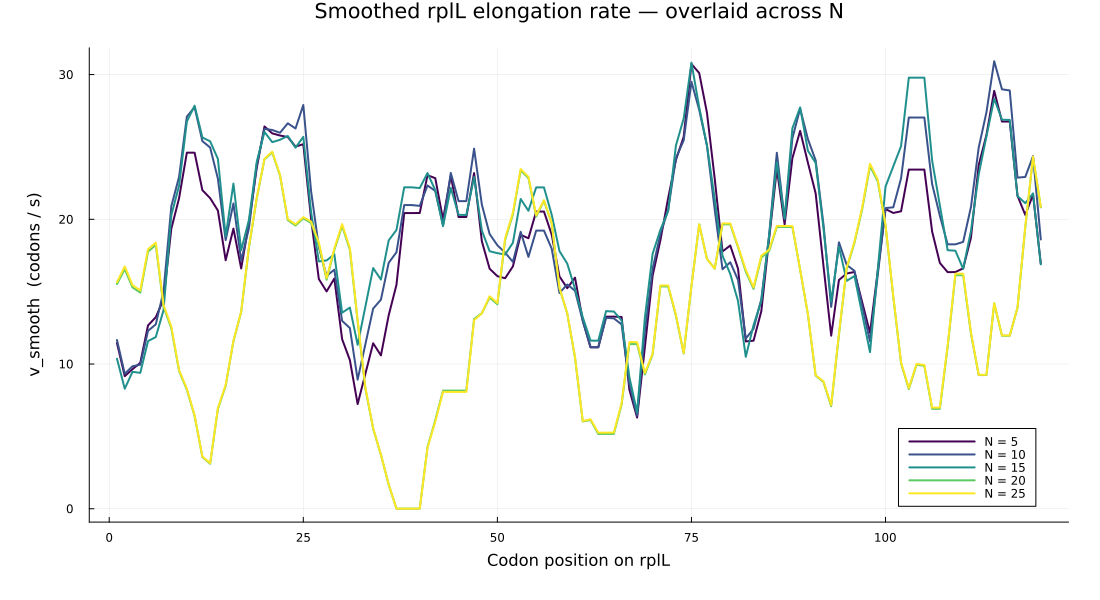

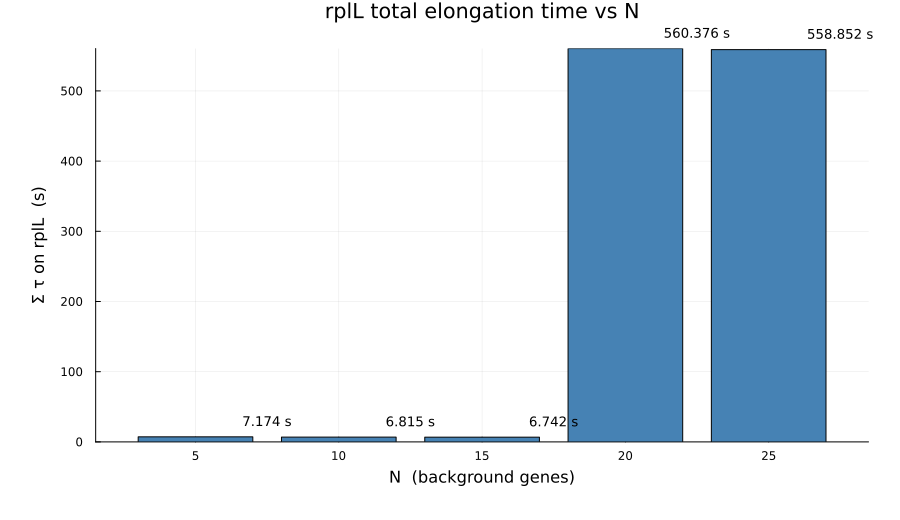

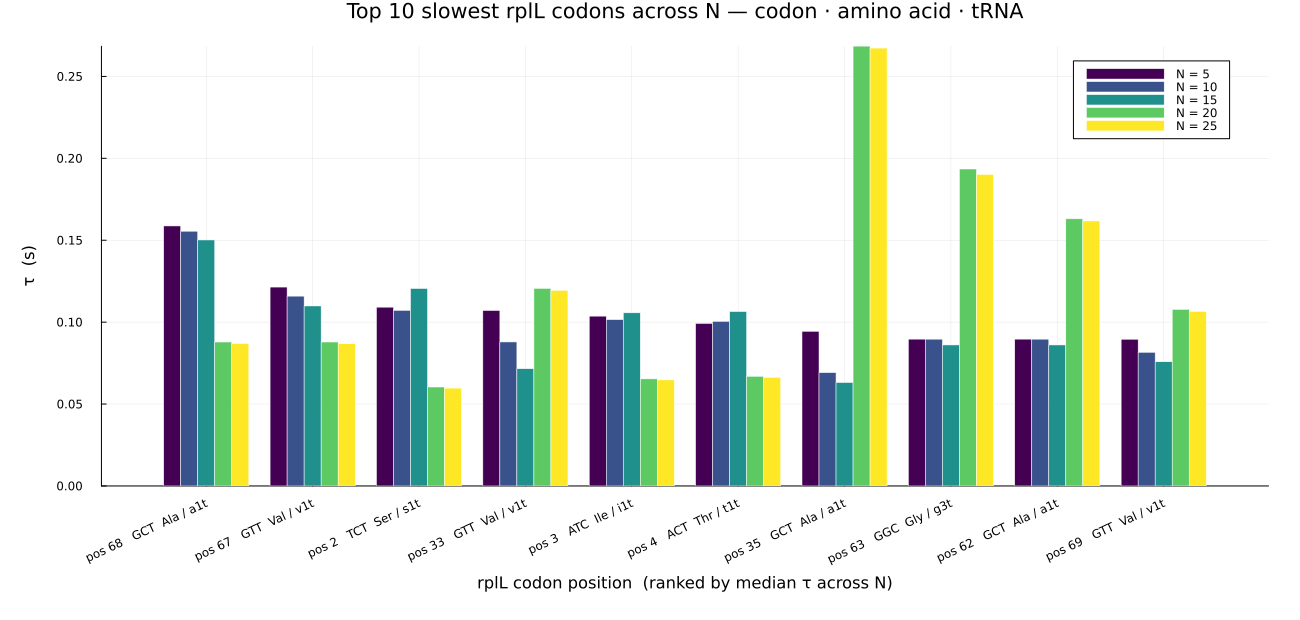

In [6]:
# ═══════════════════════════════════════════════════════════════════════════════
# Cross-N plots from the 100-min run-I sweep
#
# Reads the two appendable logs written by the simulation cell above:
#   ../data/output/elongation_rate_log.csv  — per-codon rows (120 per run)
#   ../data/output/run_summary_log.csv      — one row per run (params + key
#                                              metrics + limiting tRNA species)
#
# Produces three PNG figures into ../data/output/figures/ :
#   cross_N_v_smooth_profile.png   — v_smooth(codon) overlaid for all N
#   cross_N_sigma_tau_vs_N.png     — Σ τ on rplL vs N (invariance metric)
#   cross_N_slowest_codons.png     — top-K slowest rplL codons grouped by N
#
# Filters the log to the current run-I scale set so old/stale rows from earlier
# tuning configs are ignored. If the same N was re-run (e.g. for atol changes),
# only the LATEST timestamp for that N is plotted.
#
# Re-run this cell after every new simulation to refresh the figures.
# ═══════════════════════════════════════════════════════════════════════════════
using DataFrames, CSV, Plots, Statistics, Printf

elong_log_path       = "../data/output/elongation_rate_log.csv"
run_summary_log_path = "../data/output/run_summary_log.csv"
fig_dir              = "../data/output/figures"
isdir(fig_dir) || mkpath(fig_dir)

if !isfile(elong_log_path)
    error("Elongation log not found at $elong_log_path — run the simulation cell with status=ok at least once first.")
end

df = CSV.read(elong_log_path, DataFrame)
println("Loaded $(nrow(df)) rows from $(elong_log_path)")
println("  N values   : ", sort(unique(df.N)))
println("  bg_modes   : ", unique(df.bg_mode))
println("  V_IN_70SIC : ", unique(df.V_IN_70SIC_scale))
println("  ARS scales : ", unique(df.ARS_scale))
println("  tRNA scales: ", unique(df.tRNA_scale))
println("  EF scales  : ", unique(df.EF_scale))
println("  Rib scales : ", unique(df.Rib_scale))
println("  atol       : ", unique(df.ode_abstol))
println("  t_sample   : ", unique(df.t_sample_min))

# ─── Filter to the current run-I scale set ─────────────────────────────────────
# Strict run-I: V_IN_70SIC=20, V_IN_IF2D=2, ARS=20, tRNA=1.7, Rib=2 (EF=√Rib≈1.414).
# Adjust target_* values if you sweep a different config.
target_mode       = "first"
target_V_IN_70SIC = 75.0
target_V_IN_IF2D  = 2.0
target_ARS        = 20.0
target_tRNA       = 1.0
target_Rib        = 1.0

approx(a, b; rtol = 1e-3) = abs(a - b) <= rtol * max(abs(b), 1.0)

sub = filter(row ->
    row.bg_mode == target_mode &&
    approx(row.V_IN_70SIC_scale, target_V_IN_70SIC) &&
    approx(row.V_IN_IF2D_scale,  target_V_IN_IF2D)  &&
    approx(row.ARS_scale,        target_ARS)        &&
    approx(row.tRNA_scale,       target_tRNA)       &&
    approx(row.Rib_scale,        target_Rib),
    df)

@printf("\nFilter: mode=:%s  V_IN_70SIC=%.1f  V_IN_IF2D=%.1f  ARS=%.1f  tRNA=%.2f  Rib=%.1f\n",
        target_mode, target_V_IN_70SIC, target_V_IN_IF2D, target_ARS, target_tRNA, target_Rib)
@printf("  → %d rows match, N values %s\n",
        nrow(sub), string(sort(unique(sub.N))))

if isempty(sub)
    error("No rows match the filter — adjust target_* values above or run more simulations.")
end

# If the same N appears more than once (e.g. retries at different atol), keep the
# LATEST timestamp per N.
latest_ts = Dict{Any, String}()
for r in eachrow(sub)
    ts = string(r.timestamp)
    if !haskey(latest_ts, r.N) || ts > latest_ts[r.N]
        latest_ts[r.N] = ts
    end
end
sub = filter(row -> string(row.timestamp) == latest_ts[row.N], sub)

Ns = sort(unique(sub.N))
@printf("After de-duplication: plotting N = %s (latest run per N)\n", string(Ns))

# ─── Per-N summary (scalar metrics) ────────────────────────────────────────────
per_N = combine(groupby(sub, :N)) do g
    g1 = sort(g, :codon_pos)[1, :]
    (
        N             = g1.N,
        sigma_tau_s   = g1.rplL_total_time_s,
        mean_v_cs     = g1.rplL_mean_v_cs,
        T3_min        = g1.T3_min,
        T3_mean       = g1.T3_mean,
        wall_time_s   = g1.wall_time_s,
        atol          = g1.ode_abstol,
        slowest_pos   = g.codon_pos[argmax(g.tau_s)],
        slowest_tau_s = maximum(g.tau_s),
    )
end
per_N = sort(per_N, :N)
println("\nPer-N summary:")
println(per_N)

# Viridis colour map: low N = purple, high N = yellow.
palette = cgrad(:viridis, max(length(Ns), 2); categorical = true)

# ─── PLOT 1: v_smooth profile overlaid for all N ───────────────────────────────
p_vsmooth = plot(
    xlabel = "Codon position on rplL",
    ylabel = "v_smooth  (codons / s)",
    title  = "Smoothed rplL elongation rate — overlaid across N",
    legend = :bottomright, size = (1100, 600),
    left_margin = 10Plots.mm, bottom_margin = 10Plots.mm,
    right_margin = 6Plots.mm, top_margin = 6Plots.mm,
)
for (i, N) in enumerate(Ns)
    d = sort(filter(r -> r.N == N, sub), :codon_pos)
    plot!(p_vsmooth, d.codon_pos, d.v_smooth_cod_s;
          label = "N = $N", linewidth = 2, color = palette[i])
end

# ─── PLOT 2: Σ τ vs N ──────────────────────────────────────────────────────────
p_sigma = bar(
    string.(per_N.N), per_N.sigma_tau_s;
    xlabel = "N  (background genes)",
    ylabel = "Σ τ on rplL  (s)",
    title  = "rplL total elongation time vs N",
    legend = false, size = (900, 520), color = :steelblue,
    left_margin = 10Plots.mm, bottom_margin = 10Plots.mm,
    right_margin = 6Plots.mm, top_margin = 6Plots.mm,
)
let ymax = maximum(per_N.sigma_tau_s)
    for (i, row) in enumerate(eachrow(per_N))
        annotate!(p_sigma, i, row.sigma_tau_s + 0.04 * ymax,
                  text(@sprintf("%.3f s", row.sigma_tau_s), 9, :black))
    end
end

# ─── PLOT 3: top-K slowest codons across N (grouped bars) ──────────────────────
top_k = 10
median_tau_per_pos = combine(groupby(sub, :codon_pos), :tau_s => median => :median_tau)
sort!(median_tau_per_pos, :median_tau, rev = true)
top_positions = median_tau_per_pos.codon_pos[1:min(top_k, nrow(median_tau_per_pos))]

# ─── Codon → amino acid → tRNA isoacceptor lookup ──────────────────────────────
# Source: data/input/AS_and_Codon.dat. The model's alpha_one (first cognate tRNA
# row that lists the codon) is reproduced by iterating TRNA_TABLE in order and
# returning the first match — same convention as alpha_struc_generation in
# functions.jl. Use this table to translate codon positions back to
# (codon, amino acid, tRNA isoacceptor) for human-readable plot/print labels.
TRNA_TABLE = [
    (tag = "a1t", aa = "Ala", codons = ["GCU", "GCA", "GCG"]),
    (tag = "a2t", aa = "Ala", codons = ["GCC"]),
    (tag = "c1t", aa = "Cys", codons = ["UGC", "UGU"]),
    (tag = "d1t", aa = "Asp", codons = ["GAC", "GAU"]),
    (tag = "e2t", aa = "Glu", codons = ["GAA", "GAG"]),
    (tag = "f1t", aa = "Phe", codons = ["UUC", "UUU"]),
    (tag = "g2t", aa = "Gly", codons = ["GGA", "GGG"]),
    (tag = "g3t", aa = "Gly", codons = ["GGC", "GGU"]),
    (tag = "h1t", aa = "His", codons = ["CAC", "CAU"]),
    (tag = "i1t", aa = "Ile", codons = ["AUC", "AUU", "AUA"]),
    (tag = "k1t", aa = "Lys", codons = ["AAA", "AAG"]),
    (tag = "l1t", aa = "Leu", codons = ["CUG"]),
    (tag = "l2t", aa = "Leu", codons = ["CUC", "CUU"]),
    (tag = "l3t", aa = "Leu", codons = ["CUA", "CUG"]),
    (tag = "l4t", aa = "Leu", codons = ["UUG"]),
    (tag = "l5t", aa = "Leu", codons = ["UUA", "UUG"]),
    (tag = "m1t", aa = "Met", codons = ["AUG"]),
    (tag = "n1t", aa = "Asn", codons = ["AAC", "AAU"]),
    (tag = "p1t", aa = "Pro", codons = ["CCG"]),
    (tag = "p2t", aa = "Pro", codons = ["CCC", "CCU"]),
    (tag = "p3t", aa = "Pro", codons = ["CCA", "CCU", "CCG"]),
    (tag = "q1t", aa = "Gln", codons = ["CAA"]),
    (tag = "q2t", aa = "Gln", codons = ["CAG"]),
    (tag = "r2t", aa = "Arg", codons = ["CGU", "CGC", "CGA"]),
    (tag = "r3t", aa = "Arg", codons = ["CGG"]),
    (tag = "r4t", aa = "Arg", codons = ["AGA"]),
    (tag = "r5t", aa = "Arg", codons = ["AGG"]),
    (tag = "s1t", aa = "Ser", codons = ["UCA", "UCU", "UCG"]),
    (tag = "s2t", aa = "Ser", codons = ["UCG"]),
    (tag = "s3t", aa = "Ser", codons = ["AGC", "AGU"]),
    (tag = "s5t", aa = "Ser", codons = ["UCC", "UCU"]),
    (tag = "t1t", aa = "Thr", codons = ["ACC", "ACU"]),
    (tag = "t2t", aa = "Thr", codons = ["ACG"]),
    (tag = "t4t", aa = "Thr", codons = ["ACA", "ACU", "ACG"]),
    (tag = "v1t", aa = "Val", codons = ["GUA", "GUG", "GUU"]),
    (tag = "v2t", aa = "Val", codons = ["GUC", "GUU"]),
    (tag = "w1t", aa = "Trp", codons = ["UGG"]),
    (tag = "y1t", aa = "Tyr", codons = ["UAC", "UAU"]),
]

# rplL coding sequence (same as cell 2). Codon positions 1..120 are translated;
# the trailing stop codon at position 121 (TAA) is not in the elongation log.
RPLL_CDS = "ATGTCTATCACTAAAGATCAAATCATTGAAGCAGTTGCAGCTATGTCTGTAATGGACGTTGTAGAACTGATCTCTGCAATGGAAGAAAAATTCGGTGTTTCCGCTGCTGCTGCTGTAGCTGTAGCTGCTGGCCCGGTTGAAGCTGCTGAAGAAAAAACTGAATTCGACGTAATTCTGAAAGCTGCTGGCGCTAACAAAGTTGCTGTTATCAAAGCAGTACGTGGCGCAACTGGCCTGGGTCTGAAAGAAGCTAAAGACCTGGTAGAATCTGCACCGGCTGCTCTGAAAGAAGGCGTGAGCAAAGACGACGCAGAAGCACTGAAAAAAGCTCTGGAAGAAGCTGGCGCTGAAGTTGAAGTTAAATAA"

codon_at_pos(seq, pos) = uppercase(String(seq[(3 * (pos - 1) + 1):(3 * pos)]))

function aa_trna_for_codon(codon_dna)
    codon_rna = replace(codon_dna, 'T' => 'U')
    for row in TRNA_TABLE
        codon_rna in row.codons && return (codon = codon_dna, codon_rna = codon_rna,
                                            aa = row.aa, trna = row.tag)
    end
    return (codon = codon_dna, codon_rna = codon_rna, aa = "?", trna = "?")
end

top_info = [(; pos = p, median_tau_s = median_tau_per_pos.median_tau[i],
              aa_trna_for_codon(codon_at_pos(RPLL_CDS, p))...)
            for (i, p) in enumerate(top_positions)]

println("\nTop $(top_k) slowest rplL codon positions  (ranked by median τ across N=", Ns, "):")
@printf("  %-5s %-5s %-7s %-5s %-5s %-12s\n", "rank", "pos", "codon", "aa", "tRNA", "median τ (s)")
for (rank, info) in enumerate(top_info)
    @printf("  %-5d %-5d %-7s %-5s %-5s %-12.4f\n",
            rank, info.pos, info.codon, info.aa, info.trna, info.median_tau_s)
end

nN          = length(Ns)
bw          = 0.8 / nN
xpos_centre = collect(1:length(top_positions))

p_slow = plot(
    size   = (1300, 620),
    xlabel = "rplL codon position  (ranked by median τ across N)",
    ylabel = "τ  (s)",
    title  = "Top $top_k slowest rplL codons across N — codon · amino acid · tRNA",
    legend = :topright,
    xrotation = 25, xtickfontsize = 8,
    left_margin = 10Plots.mm, bottom_margin = 18Plots.mm,
    right_margin = 6Plots.mm, top_margin = 6Plots.mm,
)
for (i, N) in enumerate(Ns)
    xs   = Float64[]
    taus = Float64[]
    for (j, pos) in enumerate(top_positions)
        rowf = filter(r -> r.N == N && r.codon_pos == pos, sub)
        push!(xs,   xpos_centre[j] + (i - (nN + 1) / 2) * bw)
        push!(taus, isempty(rowf) ? NaN : first(rowf.tau_s))
    end
    bar!(p_slow, xs, taus;
         label = "N = $N", bar_width = bw,
         color = palette[i], linewidth = 0.5, linecolor = :white)
end
slow_labels = ["pos $(info.pos)   $(info.codon)  $(info.aa) / $(info.trna)" for info in top_info]
xticks!(p_slow, (xpos_centre, slow_labels))

# ─── Save and display ──────────────────────────────────────────────────────────
vsmooth_path = "$fig_dir/cross_N_v_smooth_profile.png"
sigma_path   = "$fig_dir/cross_N_sigma_tau_vs_N.png"
slow_path    = "$fig_dir/cross_N_slowest_codons.png"
savefig(p_vsmooth, vsmooth_path)
savefig(p_sigma,   sigma_path)
savefig(p_slow,    slow_path)

println("\nSaved 3 figures:")
println("  1. v_smooth profile (all N) → $vsmooth_path")
println("  2. Σ τ vs N                 → $sigma_path")
println("  3. top-$top_k slowest codons   → $slow_path")

# Display all three inline.
display(p_vsmooth)
display(p_sigma)
display(p_slow)

# Optional: peek at the run summary log (limiting tRNA per run) if it exists.
if isfile(run_summary_log_path)
    rs = CSV.read(run_summary_log_path, DataFrame)
    println("\nrun_summary_log peek (latest 8 rows):")
    show(stdout, "text/plain",
         last(sort(rs, :timestamp), min(nrow(rs), 8))[!, [:timestamp, :N, :status,
              :rplL_total_time_s, :rplL_mean_v_cs, :T3_mean, :T3_min,
              :limiting_T3_name, :limiting_T3_uM, :ode_abstol, :wall_time_s]])
    println()
end

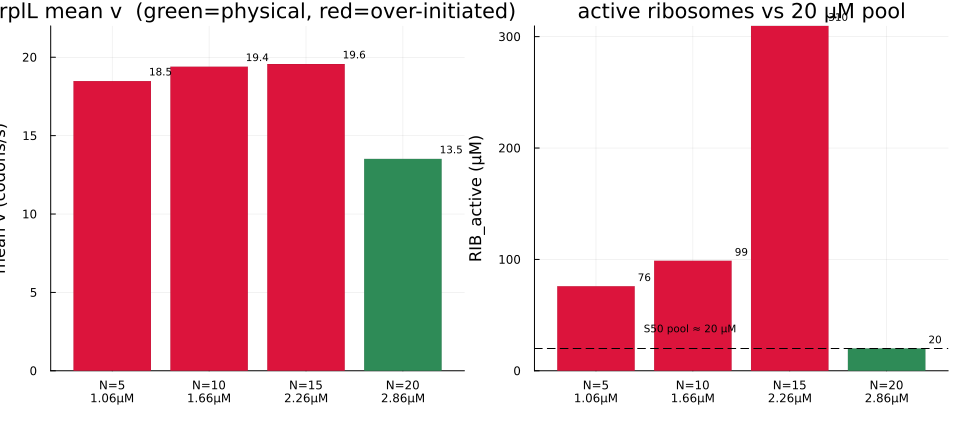

In [7]:
using Plots, Printf

N        = [5, 10, 15, 20]
total_m  = [1.06, 1.66, 2.26, 2.86]
mean_v   = [18.481, 19.399, 19.569, 13.515]   # N=10 = the n_seq=11 run
rib_act  = [75.97, 98.80, 309.65, 20.12]
S50_pool = 20.0

valid  = rib_act .<= 1.2 * S50_pool
cols   = [v ? :seagreen : :crimson for v in valid]
labels = ["N=$n\n$(t)µM" for (n, t) in zip(N, total_m)]

p1 = bar(labels, mean_v; color=cols, legend=false, lw=0, ylims=(0, 22),
         ylabel="mean v (codons/s)", title="rplL mean v  (green=physical, red=over-initiated)")
for (i, v) in enumerate(mean_v); annotate!(p1, i, v + 0.6, text(@sprintf("%.1f", v), 7)); end

p2 = bar(labels, rib_act; color=cols, legend=false, lw=0,
         ylabel="RIB_active (µM)", title="active ribosomes vs 20 µM pool")
hline!(p2, [S50_pool]; ls=:dash, lc=:black, label="")
annotate!(p2, 1, S50_pool + 18, text("S50 pool ≈ 20 µM", 7, :left))
for (i, r) in enumerate(rib_act); annotate!(p2, i, r + 8, text(@sprintf("%.0f", r), 7)); end

plt = plot(p1, p2; layout=(1, 2), size=(960, 430), bottom_margin=8Plots.mm)
display(plt)
# savefig(plt, "../data/output/figures/meanv_validity.png")

##  Subramaniam 2013 — Leu codon sensitivity



substituted sites: [42, 44, 46, 53, 60, 64, 68] | single-CTA site for C1A: 42

CTG_1        (Leu-ARS=1) Number of sequences: 1 (background_selection=first)

========== EF pool audit (literature bands: Tu/Rib ~5–9×, Ts/Rib ~1×, Tu/Ts ~5–9×, EF-G/Rib ~1.5–2.5×) ==========
  Eut (total EF-Tu, constant_vars[13])     = 224.14529514482248 µM
  Est (EF-Ts, constant_vars[14])          = 19.45182200314482 µM
  S50 (50S subunit, state after balance)  = 20.08605671156839 µM
  c_EFG_t (DAE total EF-G, parameters.jl) = 39.56753084105652 µM
  EFG+EGT+EGD (state after EF_balance!)   = 39.56753084105652 µM  (should ≈ c_EFG_t)
  Eut/S50      = 11.159248346427697   [~5–9]
  Est/S50      = 0.9684241303541532   [~~1]
  Eut/Est      = 11.523100258093274   [~5–9]
  c_EFG_t/S50  = 1.9699003845920608   [~1.5–2.5]
========== end EF pool audit ==========

  Solver: FBDF  rtol=1.0e-8  atol=0.0001  maxiters=5000000  (n_seq=1)
Integration completed!
jam?  Στ=17.46 winτ=0.54 ctaτ=0.00 PRT=1.746 RIB=20.1 CTApool=0.3

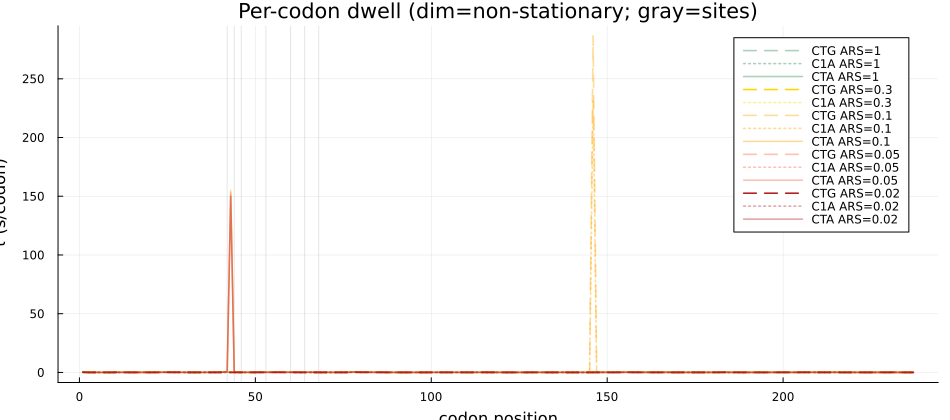

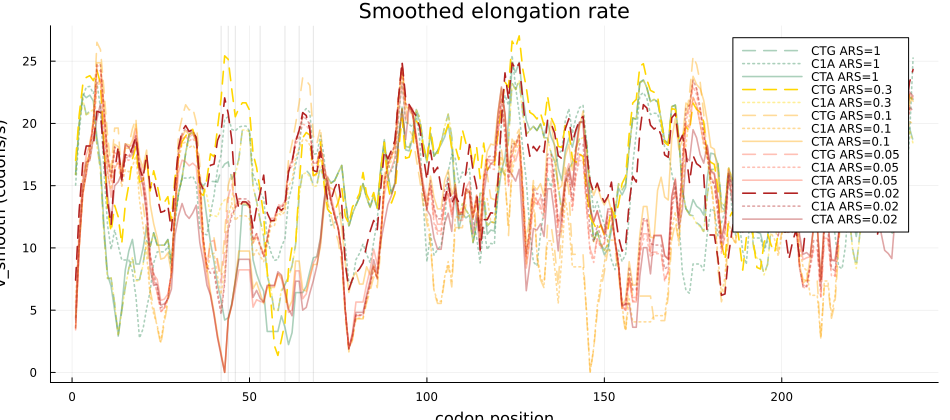

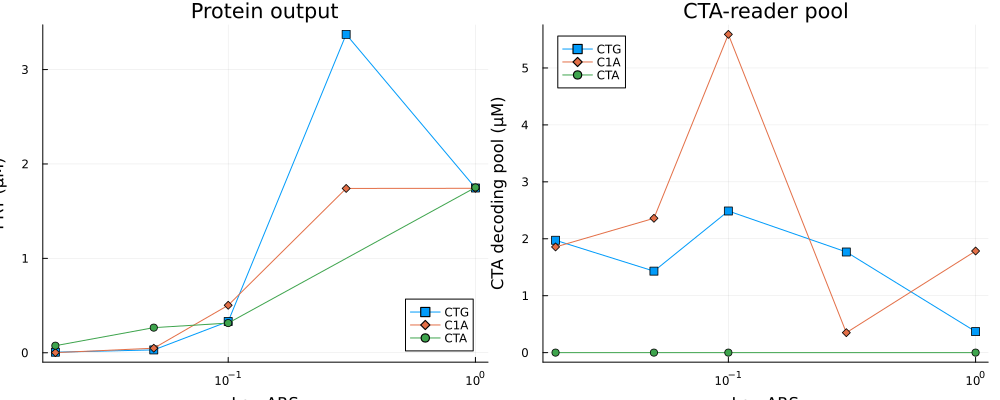

In [4]:
# ════════════════════════════════════════════════════════════════════════════
#  Subramaniam 2013 — Leu codon sensitivity, single gene, Spindler scale=1.
#  v5: (a) RIB-divergence retry restored (atol 1e-6, triggered on RIB>RIB_MAX only);
#      (b) third reporter C1A = yfp0 with ONE Leu site → CTA (titratable);
#      (c) t_end left at default 100; relative-time drift (te vs te-20).
# ════════════════════════════════════════════════════════════════════════════
using CSV, DataFrames, Statistics, Printf, Plots
include("goodman_2013.jl")

# ── knobs ───────────────────────────────────────────────────────────────────
prim       = "rplL"
LEU_IDX    = 10
LEU_LEVELS = [1.0, 0.3, 0.1, 0.05, 0.02]
m_reporter = 1.0
base_fasta = "Ecoli_K12_MG1655_geneset_with_welch_2009.fa"
pnas_fasta = joinpath("data","PNAS_2013","sd02.txt")
out_subdir = "pnas_leu_single_v5"
timeout_s  = 1800
ATOL0, ATOL_RETRY = 1e-4, 1e-6
RIB_MAX    = 100.0
SS_TOL     = 0.15

# ── reporters: yfp0 (CTG), yfp1 (7×CTA), and C1A = yfp0 with ONE site → CTA ──
recs = read_fasta_ordered(pnas_fasta)
getrec(p) = last(recs[findfirst(r -> startswith(first(r), p), recs)])
yfp0, yfp1 = getrec("yfp0"), getrec("yfp1")
cods0 = [yfp0[i:i+2] for i in 1:3:length(yfp0)]
cods1 = [yfp1[i:i+2] for i in 1:3:length(yfp1)]
sens_pos = findall(k -> cods0[k] != cods1[k], eachindex(cods0))
one_site = sens_pos[1]
cods_1 = copy(cods0); cods_1[one_site] = "CTA"
yfp_1cta = join(cods_1)
@printf("substituted sites: %s | single-CTA site for C1A: %d\n", string(sens_pos), one_site)

# (prefix, seq, linestyle, marker, cta_sites)
reporters = [
    ("CTG", yfp0,     :dash,  :square,  Int[]),
    ("C1A", yfp_1cta, :dot,   :diamond, [one_site]),
    ("CTA", yfp1,     :solid, :circle,  sens_pos),
]

mk_scale(la) = (ars = ones(20); ars[LEU_IDX] = la; txtl_types.make_scale(
    V_TC_scale=1.0, k_TLEmaxj_scale=1.0, V_IN_70SIC_scale=1.0, V_IN_IF2D_scale=1.0,
    Rib_scale=1.0, IF_scale=1.0, EF_scale=1.0, tRNA_scale=1.0,
    ARS_scale=ars, RibRecycling=0.0, V_mDeg_scale=0.0))

base_records = read_fasta_ordered(joinpath("..","data","sequences", base_fasta))
het_conc = Dict(prim => m_reporter)

function _run(f, ts)
    ch = Channel{Any}(1)
    t  = @async try; put!(ch,(:ok,f())); catch e; put!(ch,(:error,e)); end
    t0 = time(); while !istaskdone(t); time()-t0>ts && return (:timeout,nothing,time()-t0); sleep(0.5); end
    s,p = take!(ch); return (s,p,time()-t0)
end

function decode_pools(payload, gene, te)
    p = payload.p; si = _find_seq_index(p, gene); tg = p.local_tags_list[si]
    us = extract_u_sequence(payload.sol(te), p, si); ns = tg.num_species
    cC = tg.t3_Codon_struc * reshape(max.(us[1:ns], 0.0), 1, ns)'
    ci = tg.species_and_sequences.cod_idx
    poolof(target) = begin
        for (k, v) in ci; string(k) == target && return cC[v]; end
        return NaN
    end
    return (cta = poolof("CUA"), ctg = poolof("CUG"))
end

profiles = Dict{String,Any}(); rows = NamedTuple[]
mkpath(joinpath("..","data","sequences",out_subdir)); mkpath("../data/output/figures")

function one_solve(cds, la, atol, rel)
    write_fasta_with_replacement(base_records, prim, cds, joinpath("..","data","sequences",rel))
    _run(timeout_s) do
        call_model(rel, [prim], 0; custom_scale=mk_scale(la), growth_rate=1, het_mRNA_conc=het_conc,
            return_details=true, return_sol=true, static_EFs=true, spindler_75pct=false,
            ode_reltol=1e-8, ode_abstol=atol, ode_maxiters=5_000_000)
    end
end

function eval_metrics(payload)
    te     = float(payload.sol.t[end])
    spEnd  = spindler_codon_translation_time(payload.sol, payload.p, prim; t_sample = te)
    spPrev = spindler_codon_translation_time(payload.sol, payload.p, prim; t_sample = max(te - 20, payload.sol.t[1]))
    dg     = collect_pool_diagnostics(payload.sol, payload.p, te; primary_gene=prim)
    dp     = decode_pools(payload, prim, te)
    drift  = abs(spEnd.total_time_s - spPrev.total_time_s) / max(spEnd.total_time_s, 1e-9)
    (te=te, sp=spEnd, dg=dg, dp=dp, drift=drift)
end

function run_case(label, cds, la, cta_sites, ls)
    rel = joinpath(out_subdir, replace(label, r"[^A-Za-z0-9_]"=>"_") * ".fa")
    @printf("\n%-12s (Leu-ARS=%.3g) ", label, la); flush(stdout)
    atol = ATOL0
    status, payload, _ = one_solve(cds, la, atol, rel)
    ok = status==:ok && payload!==nothing && successful_retcode(payload.sol)
    m  = ok ? eval_metrics(payload) : nothing
    if ok && m.dg.RIB_active > RIB_MAX                 # retry ONLY for numerical RIB blow-up
        @printf("[retry %.0e: RIB=%.0f] ", ATOL_RETRY, m.dg.RIB_active); flush(stdout)
        atol = ATOL_RETRY
        status, payload, _ = one_solve(cds, la, atol, rel)
        ok = status==:ok && payload!==nothing && successful_retcode(payload.sol)
        m  = ok ? eval_metrics(payload) : nothing
    end
    if ok
        stationary = (m.te >= 100-1e-9) && (m.dg.RIB_active <= RIB_MAX) && (m.drift <= SS_TOL)
        win = filter(p -> p <= m.sp.L, sens_pos)
        cs  = filter(p -> p <= m.sp.L, cta_sites)
        profiles[label] = (tau=m.sp.tau, v=m.sp.v_smooth, stationary=stationary, ls=ls)
        r = (label=label, leu_ars=la, stationary=stationary, stot=m.sp.total_time_s,
             win_tau=sum(m.sp.tau[win]), cta_tau = isempty(cs) ? 0.0 : sum(m.sp.tau[cs]),
             mean_v=m.sp.mean_v, PRT=m.dg.PRT_primary, RIB=m.dg.RIB_active,
             cta_pool=m.dp.cta, ctg_pool=m.dp.ctg, drift=m.drift, atol=atol)
        @printf("%s Στ=%.2f winτ=%.2f ctaτ=%.2f PRT=%.3f RIB=%.1f CTApool=%.3g drift=%d%%",
                stationary ? "ok   " : "jam? ", r.stot, r.win_tau, r.cta_tau, r.PRT, r.RIB, r.cta_pool, round(Int,100r.drift))
    else
        r = (label=label, leu_ars=la, stationary=false, stot=NaN, win_tau=NaN, cta_tau=NaN,
             mean_v=NaN, PRT=NaN, RIB=NaN, cta_pool=NaN, ctg_pool=NaN, drift=NaN, atol=atol)
        @printf("FAILED (%s)", status)
    end
    push!(rows, r); return r
end

for la in LEU_LEVELS, (rep, seq, ls, mk, cs) in reporters
    run_case(@sprintf("%s_%.3g", rep, la), seq, la, cs, ls)
end
res = DataFrame(rows); CSV.write("../data/output/pnas_leu_single_v5.csv", res)
println("\n\nSaved → ../data/output/pnas_leu_single_v5.csv"); show(res, allcols=true); println()

# ── gate: C1A should now show a GRADED CTApool fall (1 CTA ≠ instant exhaustion)
println("\nGate — CTA decoding pool vs Leu-ARS (C1A = titratable, CTA = saturated):")
for rep in ("C1A","CTA")
    for r in eachrow(sort(filter(x->startswith(x.label,rep), res), :leu_ars, rev=true))
        @printf("  %-3s Leu-ARS=%.3g  CTApool=%.3g  ctaτ=%.3g  stationary=%s\n",
                rep, r.leu_ars, r.cta_pool, r.cta_tau, r.stationary)
    end
end

# ── plots: τ and v profiles (all successful; non-stationary dimmed) ──────────
pal = Dict(1.0=>:seagreen, 0.3=>:gold, 0.1=>:orange, 0.05=>:tomato, 0.02=>:firebrick)
function prof(field, ylab, title)
    plt = plot(xlabel="codon position", ylabel=ylab, title=title, legend=:topright, size=(950,420))
    for p in sens_pos; vline!(plt, [p], c=:gray, alpha=0.2, label=false); end
    for la in LEU_LEVELS, (rep, seq, ls, mk, cs) in reporters
        k = @sprintf("%s_%.3g", rep, la); haskey(profiles,k) || continue
        y = getproperty(profiles[k], field)
        al = profiles[k].stationary ? 1.0 : 0.4
        plot!(plt, 1:length(y), y, lw=1.6, ls=ls, c=get(pal,la,:black), alpha=al,
              label=@sprintf("%s ARS=%.3g", rep, la))
    end
    plt
end
pA = prof(:tau, "τ (s/codon)", "Per-codon dwell (dim=non-stationary; gray=sites)")
pB = prof(:v,   "v_smooth (codons/s)", "Smoothed elongation rate")

# ── titration: PRT and CTA-pool vs Leu-ARS, per reporter ─────────────────────
succ = filter(x->isfinite(x.PRT), res)
pP = plot(xlabel="Leu-ARS", ylabel="PRT (µM)", title="Protein output", xscale=:log10, legend=:bottomright)
pQ = plot(xlabel="Leu-ARS", ylabel="CTA decoding pool (µM)", title="CTA-reader pool", xscale=:log10, legend=:topleft)
for (rep, seq, ls, mk, cs) in reporters
    d = sort(filter(x->startswith(x.label,rep), succ), :leu_ars)
    nrow(d)==0 && continue
    plot!(pP, d.leu_ars, d.PRT, m=mk, label=rep)
    plot!(pQ, d.leu_ars, d.cta_pool, m=mk, label=rep)
end
pC = plot(pP, pQ, layout=(1,2), size=(1000,400))

savefig(pA, "../data/output/figures/v5_dwell.png")
savefig(pB, "../data/output/figures/v5_velocity.png")
savefig(pC, "../data/output/figures/v5_summary.png")
println("Figures → ../data/output/figures/v5_{dwell,velocity,summary}.png")
display(pA); display(pB); display(pC)

Saved → ../data/output/figures/subramaniam_validation.{png,pdf}

C1A CTA-site dwell vs Leu-ARS (fold vs baseline):
  ARS=0.02  Στ_site=0.215 s  (3.8×)  quasi-SS
  ARS=0.05  Στ_site=0.201 s  (3.5×)  quasi-SS
  ARS=0.1  Στ_site=0.160 s  (2.8×)  quasi-SS
  ARS=0.3  Στ_site=0.074 s  (1.3×)  quasi-SS
  ARS=1  Στ_site=0.057 s  (1.0×)  quasi-SS


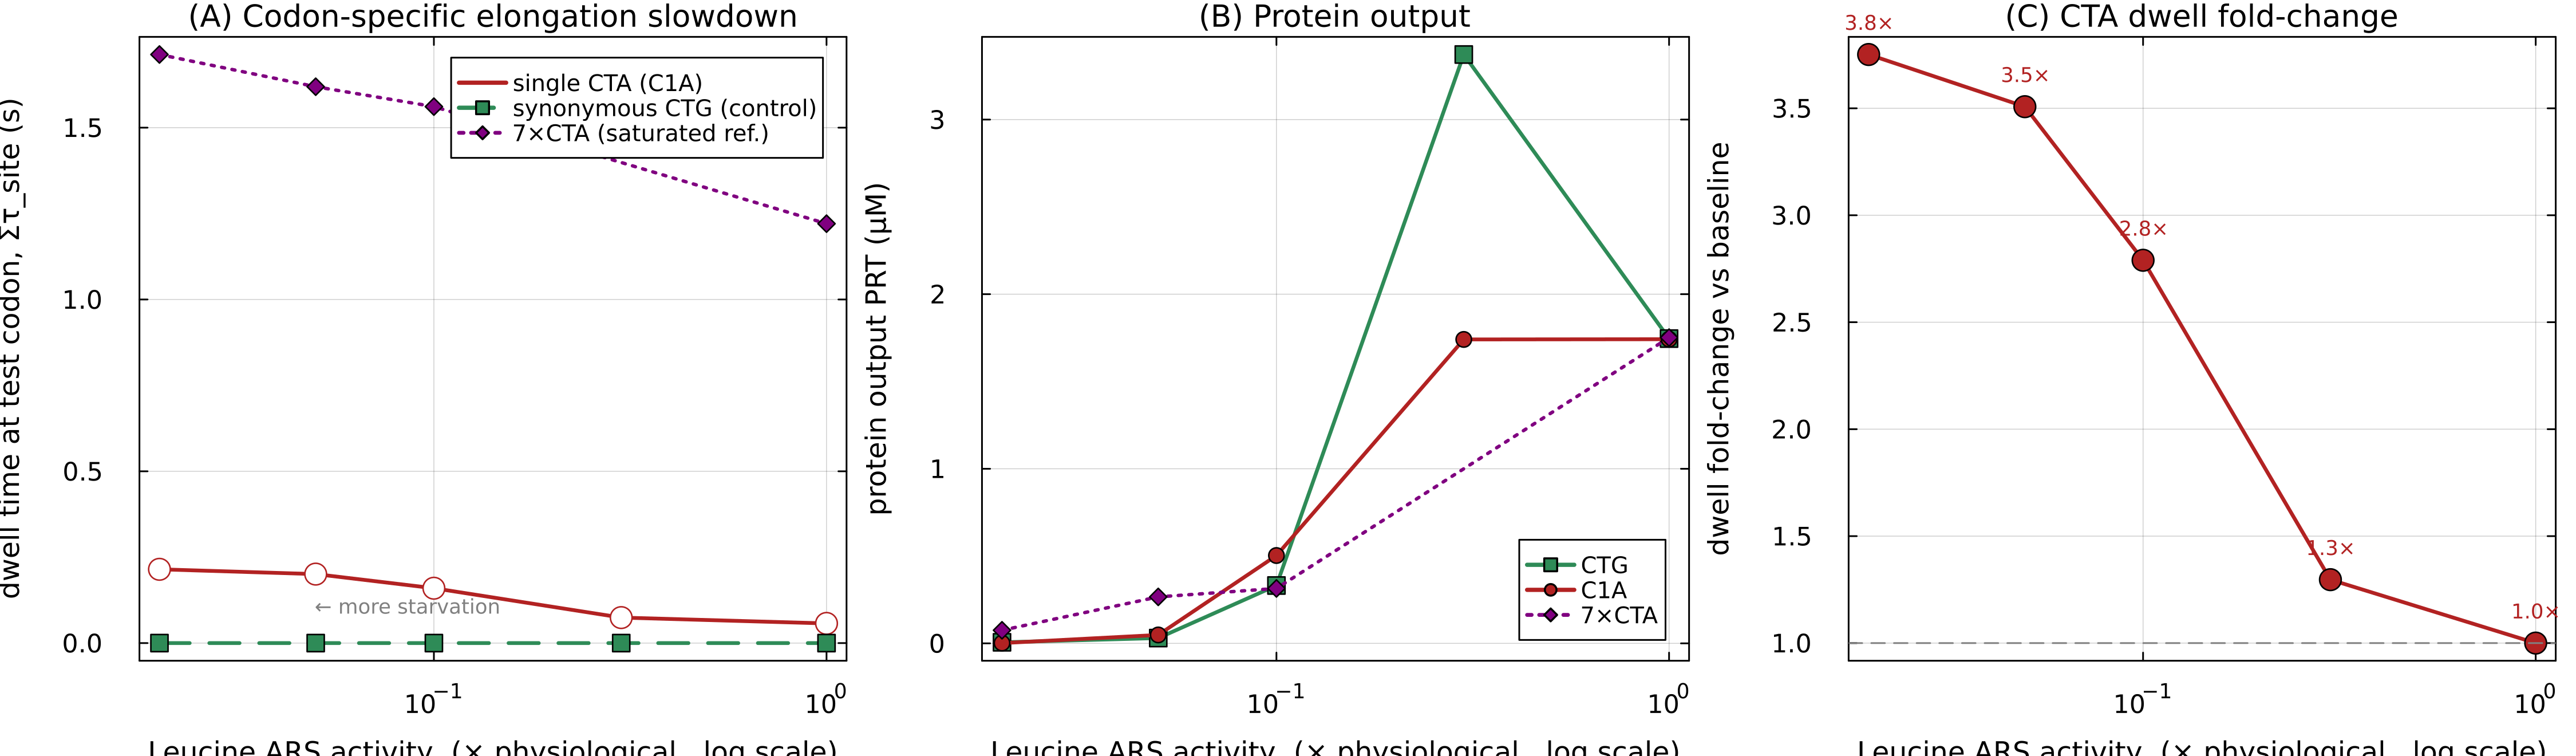

In [2]:
# ════════════════════════════════════════════════════════════════════════════
#  Publication figures — PNAS-2013 leucine codon-specific elongation validation.
#  Reads ../data/output/pnas_leu_single_v5.csv (standalone; no model rerun).
# ════════════════════════════════════════════════════════════════════════════
using CSV, DataFrames, Statistics, Printf, Plots
gr()
default(fontfamily="sans-serif", guidefontsize=11, tickfontsize=10,
        legendfontsize=9, titlefontsize=12, framestyle=:box, grid=true, dpi=300)

df = CSV.read("../data/output/pnas_leu_single_v5.csv", DataFrame)
ser(pre) = sort(filter(r -> startswith(r.label, pre) && isfinite(r.PRT), df), :leu_ars)
ctg, c1a, cta = ser("CTG"), ser("C1A"), ser("CTA")

# open markers = quasi-steady-state (drift>15%), filled = stationary — honest reporting
mfc(d, col) = [s ? col : :white for s in d.stationary]

# ── Panel A: codon-specific dwell dose–response ──────────────────────────────
pA = plot(xlabel="Leucine ARS activity  (× physiological,  log scale)",
          ylabel="dwell time at test codon, Στ_site (s)",
          title="(A) Codon-specific elongation slowdown",
          xscale=:log10, legend=:topright)
plot!(pA, c1a.leu_ars, c1a.cta_tau, lw=2.2, c=:firebrick, label="single CTA (C1A)")
scatter!(pA, c1a.leu_ars, c1a.cta_tau, m=:circle, ms=7, c=mfc(c1a,:firebrick),
         msc=:firebrick, label=false)
plot!(pA, ctg.leu_ars, fill(0.0, nrow(ctg)), lw=2.2, ls=:dash, c=:seagreen,
      m=:square, ms=5, label="synonymous CTG (control)")
plot!(pA, cta.leu_ars, cta.cta_tau, lw=2.0, ls=:dot, c=:purple, m=:diamond, ms=5,
      label="7×CTA (saturated ref.)")
annotate!(pA, 0.05, maximum(c1a.cta_tau)*0.5, text("← more starvation", 8, :gray, :left))

# ── Panel B: functional output (protein) ─────────────────────────────────────
pB = plot(xlabel="Leucine ARS activity  (× physiological,  log scale)",
          ylabel="protein output PRT (µM)",
          title="(B) Protein output", xscale=:log10, legend=:bottomright)
plot!(pB, ctg.leu_ars, ctg.PRT, lw=2.2, c=:seagreen, m=:square,  ms=5, label="CTG")
plot!(pB, c1a.leu_ars, c1a.PRT, lw=2.2, c=:firebrick, m=:circle,  ms=5, label="C1A")
plot!(pB, cta.leu_ars, cta.PRT, lw=2.0, c=:purple, m=:diamond, ms=5, ls=:dot, label="7×CTA")

# ── Panel C: fold-change of the CTA-specific dwell (C1A) ─────────────────────
rich = c1a.cta_tau[findfirst(==(1.0), c1a.leu_ars)]
fc   = c1a.cta_tau ./ rich
pC = plot(c1a.leu_ars, fc, lw=2.2, c=:firebrick, m=:circle, ms=7,
          xlabel="Leucine ARS activity  (× physiological,  log scale)",
          ylabel="dwell fold-change vs baseline",
          title="(C) CTA dwell fold-change", xscale=:log10, legend=false)
hline!(pC, [1.0], ls=:dash, c=:gray)
for (x,y) in zip(c1a.leu_ars, fc); annotate!(pC, x, y+0.15, text(@sprintf("%.1f×", y), 8, :firebrick)); end

fig = plot(pA, pB, pC, layout=(1,3), size=(1500,440), left_margin=6Plots.mm, bottom_margin=6Plots.mm)
mkpath("../data/output/figures")
savefig(fig, "../data/output/figures/subramaniam_validation.png")
savefig(fig, "../data/output/figures/subramaniam_validation.pdf")
println("Saved → ../data/output/figures/subramaniam_validation.{png,pdf}")

# numbers for the figure caption / text
@printf("\nC1A CTA-site dwell vs Leu-ARS (fold vs baseline):\n")
for (x,y,f,s) in zip(c1a.leu_ars, c1a.cta_tau, fc, c1a.stationary)
    @printf("  ARS=%.3g  Στ_site=%.3f s  (%.1f×)  %s\n", x, y, f, s ? "stationary" : "quasi-SS")
end
display(fig)

# Spindler ACS RTS comparsion part

In [2]:
# ─── Packages, functions ───
include("packages.jl")
using DataFrames, CSV, Printf, Plots
include("functions.jl")
gr()

# ─── Sequences ───
rplL_seq = "ATGTCTATCACTAAAGATCAAATCATTGAAGCAGTTGCAGCTATGTCTGTAATGGACGTTGTAGAACTGATCTCTGCAATGGAAGAAAAATTCGGTGTTTCCGCTGCTGCTGCTGTAGCTGTAGCTGCTGGCCCGGTTGAAGCTGCTGAAGAAAAAACTGAATTCGACGTAATTCTGAAAGCTGCTGGCGCTAACAAAGTTGCTGTTATCAAAGCAGTACGTGGCGCAACTGGCCTGGGTCTGAAAGAAGCTAAAGACCTGGTAGAATCTGCACCGGCTGCTCTGAAAGAAGGCGTGAGCAAAGACGACGCAGAAGCACTGAAAAAAGCTCTGGAAGAAGCTGGCGCTGAAGTTGAAGTTAAATAA"

rts_seqs = Dict(
    "C_eCU_1" => "ATGCGTCCGTCTTTCCATACTCGCCGTTCTTGGGCAGCGCAGGTCAACGTGAAAGCCGGCGGTACGGCTGCGTGTAAACTGCAAGACGCTCAGTTCCGTGTGTACTATCTGTCTATCCGCGGCCCGAGCCACGAGGTCAATGTTGGTGACAAGGACAATCTGGTCGCAGGCGGTCGCATCGATCTGGAGGCCATCGCACGTATCGAAAAAACGGGCCTGTTCAAACTCGATCGATTGGCAAAAGACTTCTTCCGCGCGTTCGGTGAAGTGCCAGGTATGCTTGCGATTATCTTAGAAGTATATCACCAGTATGGTATTGGCTGGGGCTTAGCATCCTCCAGCGCGCAGCGTGACAGTGGAAGCGAACTGGAACGTTCTGCTGTGAACGAACGTAATTCGACCACTTGCCGTGACCAGTGTGATCGCATGAACGCTCGTATTGGCATGGCTGGTAAACAGCCGGAATTCAATACGGTGGGAACCGGCAAGCGCAACTTCGGCGACGTATCGCAATACGGCCGTTTGCAGCATATTATCGAAGCTGGCGCAAAAATGGCCCTGGCCCGCCGTACTGACCATGACGGTGTTGCGAAGGAGACGTTGGTTGCCGAAGAGATTACATACGATACCACCCTGGTGCGCGGTACCATAGTTGAAGCTCAAGAAGTTAGCCCAGACTATACTCCTGCTGCGGGCCAGGTGGAGCTGTCGACGTATCTCGCTCTGTCAGGTAAACGTGATGACCAATTTGGTTTTTTAGGGGAAAACACACCGGCTGGCTTTAAAGTTAAAACCATCGATCATGGTTTTTACAACATCGCGAACCGTGAAAACGTGCTGTGGCAGGCGGTCTCTTCCGAAGAAAGCGAGAAAGTGAATCTGCTGTTGCCGCCTCCGATGAAAACCTGGACTCAAAGCGATACCTGGCTGAAAATTGAACTGAGTCGCCCGTCCCCGATTCAAGTCGGTGACAGCATGGGCCACGCAGATCGCGTCACAGCTTTTGCCCCCACCCGTGCGAACACCCGTGAGCTGCAGAAACAAGCACTGGTTGGTATTATCAAAGATTTTTACGACATCCGTCGCGTGAAACTGGCAAACCCCTTTCAGGATGTGGATGTTATCGTGATGGAAGTAGATCTTCCGCCGGCCATCAAAATCGTTGGGTGCGGGCTGACCTACATTGTACACTTACAGGAAGTTCCGGCTCCAAACCTGAATATTGGTTCATTTCAGTACGGTGATTATCTTGTTAAGACCATGGTTATCGAGGCGCGCGCCAAGCTCCCTGGTCTCTTCCTGAAAGATATGTTGATGGGAGCATGCAATAAAAAGAACAAACCGGCGGCCAAAATGTACCTGCCACCGTCCTTCAGTGCGGCGAGCGAAAACGGCCAGCTGCATGAATCTAACCACATGAAATTCCTGGCAGAACTTGGCGTCGATCTCCAGAAAATCGAGGTTTTTGATGAAATCCTGGAACACAACGATATTTCACTGCTAACTGTTTGGCTGATTGCCACTGCGACCACCTATCGGGAGGGCATTTTACTGGTAAAAGTACAGCTGGAATCTGCCGTAGTGAGAATCCTGCCGGACGCGCTGGCCGCGGGGATCACCGAAAAGGAACTGGAAGGTGGCGCGTCCGCAATGATTGGTGCTGTAGTTACGCAGTAA",
    "C_eCU_2" => "ATGTCTGCTGGGCCAACAGGTAACGTTCTGAAATTCGCTCTGGACCCGGAATATGAGATCATCTACGCCGGTCCTCAAGTGGATTTAGCCAACATTGCGTGCGTCTTTGCGTCAGCGCCGAACGATAACGCGCGTAACGTAGTTGCATTTGGTAGCGGCGCTGATATCGAAGGTTTCCTTATGACCCGCGGCGCCCAGAATGAAGCGATGGGGACCCTGCTGGATGAACCAAAAGAAGACGGTAAGATGGGCACGATTAAAATCGTACTGCAAATGAAGGCAGAGGACTTGTTCCGTGATGCCAGCAACACTGTGGCACGCAAAATCGATTTCATACACGAAGGCGTGAAAGGCTTCTACGAGGGGCAGGTGAAACAGTACCTTGCTGGTTCCAAGCCCGCAACCATTACCCGTACGGACCGTACAGATGGTGGTGCATACGAACAGCGGGAGTTGGATTTGTACATGATCGACAACCGTATCATCGCGGCTTCTAACAAATCCCAGGATATTCACGCAGAGGTTGTTGGCGGCACACACACTGAAACCTTAAAACGCGTTGAGGTTTGGTGGCCGGACCAAGCTCACTACTTTGCCAGCCTGATCCGCGCCATGCTGCGTGTCGAAGATGCGTATAAACGCCCGCAGCCGGACATGGAGGCCGCACTGCATGGTTACTGGCTGTCCAACCTGGAAAGAAAAGGCTCGTCCGATGTTTTTGACAAAAGTTTGCAAGGAGCGCTTCTGATTGCACATGCGGGTAAAACTTGTGGCACGAACCCGACTCCGGGTACCGTTGCGTATATTGTGACCTTCCCGTTCCGCGAAAAATTCATCCCGGAGGTGTATCTGATTCTGGAACGTGTTCTGTCTGAAGGTCGTATGAATGAAGGTCGTTTTGTGCAGTGGAACGATAAAGCTATTACTGTGGGCGAAGGCCTGGCGGAAGGAACCCAATCAAAGTTGTTTAAAAGTCTGGCTCTGTTACGAACTCCAGAAACCCTGTCCGTTCATCTGGAAATTTATCAGCGCGTCCGCGGTCCGCAGATCGTTGGCCTGGGTCCCATGTTTGACATTACGATCGCTTGCCAGGTGACCGCGAATGTCCCGTCGGTCCGTTATCTGATCCTGTTACTGCAGAGTCCTACCCAGCACGTACGTAACATGCTGAAAGCGCAGATTGACTCTCAATTTCTAATCCTGCGTAGCAAAGTGAAACACCTCGCTACCGGACGCCTCGGTCAACAGGTTAAATATGATGAACTGAAGTCTATCACCGCGTTCACCATGACGCAGGAAGCACGCGATGGTCCTGAAGGCTGCCTGTGTTTCCTCGTAAGCAAAATCTCACGCGCCGCACTTGATGCTGACCATGATCTGAAACCGTTAAATATGGTACTGTTCGCCATCGCTACCAAGCTGGGCCGCCCGGTTCTCGACCTGAAAATTGCAGAAGAAGTCAAAGAAAATGGCGTAAACGATGAGGGCACTAACGTAGCGGGTCGTTTTACGTACGCCGCTCTGGCAGGGGAGGTGCCGCGTTCTATTGAAGTTAATCAGCAGGACAGCGCGGGCGAAATGGCCCTCATTCGTAAAGAAAATTGGGGCGGTTGGTCGAACAAGGCGGACGTGCCAGTCGTAGCGGTGAGCCATTCCTCTGCCGTTATCAGCCGTTAA",
    "C_eCU_3" => "ATGGCAGTCGTTGAGTTCGAACAACCCTATCAGATGAAAGATGTGACCATGGCATGCGTAGCTGGTGACCATGCATTGCTTGGCGTCAAACTGATTCTGTTCGAACAGATGGGTCGTGGCAATGCTACCGCTTCAGTTACTCGTTCTAACAAAGGTCGCTTGGCCTTAATGGACTCCCCGTTAGGAGTGGGTGTGTACATCGCGAAACAGGAACTGCCTGAAAAGCAGGGGGACGTGTTTGCCTTCCTGTTCCAGCAGAATGAACCAGAATTCGGCCTGCAGGTTGCGGCGGATCTGGAGCGCCAGATGACGATTGTAAAGGATCCGGCACTGGAGTACATCCCAGCCCGCGGCAGATACAAGAAATATATCGCACTCTGGATTCAGGATGCAGCAGAAGGCGGTGTAAGCGACGCCGAAGCGGCTCGCTTTTTCTCGAAAGGTGTGTGCGAAGATTTTACTATTATGCGCGACGCCTTTAAAGGTTGGGGCCTGAACGTCGTCGTAGATCCGATCGTTGGGAAAGGCCTGTCCGAAAACGTCCTGAGCAACAGTGCAGCCGGCGATTTTGGCGTGGCAATTGCTGCTCGTCTGATCCGCAGCACTAAATACTATGTCTCCAGTTCCATCCTGATGGCTCAAAAAATGAAACACAATGCAGATCACTCAAAAACGGCGGTTCTGGCCATTCCGGCCAAAGCTGAGAATATTAACGGTACCATCGTTCGTGGTGCGACCACTAATGCAGACGAGCTGCCGCATACCGCTCATGTGCTGCGTGGGAAAAGCAAACGCGAGCACGATGAGGAACGACTGGGTTTATTAACCGCGCAGCTGCACACCCACGGTACGTCTGAAGACGTTTGTTACGCGCGCGTCGTGGCCTCTGAAGACCGGGAAGGCGAAGTTAATCTTGCAAGCAAACATGTTGGCGGTGCCCGTGGCATTGCGGAAGGTGGCGCTAACACTATCCGCGAGGCTGGCAACACTTATCGTACGACCGCGGGGGCGCTGCAAAAAGTTCGTAACGTACGCAGCGAGATGCAGTTTATCCCGGCGCTGGCTGCTGAGATCGATGTACTGAGCGATCTGTTCGACGCCAGTGGTAAAGATGTTAAACGTCTGCAGCTATGTATGTTCGGTCCAAACCAAAAGCAGGAAAAGCTGATCATTTATTTTGTGGGCCCGCCGCATTATCCTTCTACTGTGAAAAAGATCACAGCGGAACTGTCACTGCAAGTAATCGATGAATGGATTACCTTCTGCATGTTGTACCTGTGGCGTACCCTTGTGAAAGCGAAAGCGCGTGAAGGTGTTACCCTGTACCCATTTGACTTCACGGACATTATGATATTCCTGGACCGTCCGTGGACGGACTCTCTCACCCTCGTGCAATGGAAAATCGATAAGGTTTTAGCCCGTAACTCGGAAAACATTAACCGCCCGGAATCTGGACTGCTGCGTCACAAACCTAACAACGCGGTTGTAGATATGACCATCCCCATCATTGCGTCCACAGGCCAGCTGTTGGAAGAAGGTCTTCCGAGCTTTGAACCGTCCCGTTATACCCCGCGCGGCGTTGAACAGCAGAATATTTCGCAGGGTCCGACAGGATCTATCCTCGGTTTGACCGATAACGCGGAACTGGATGTGATCTACGACCAAGGCCTCCGTTAA",
)

🔧 Julia started with 12 threads


Dict{String, String} with 3 entries:
  "C_eCU_2" => "ATGTCTGCTGGGCCAACAGGTAACGTTCTGAAATTCGCTCTGGACCCGGAATATGAGATCATC…
  "C_eCU_3" => "ATGGCAGTCGTTGAGTTCGAACAACCCTATCAGATGAAAGATGTGACCATGGCATGCGTAGCT…
  "C_eCU_1" => "ATGCGTCCGTCTTTCCATACTCGCCGTTCTTGGGCAGCGCAGGTCAACGTGAAAGCCGGCGGT…

Spindler comparison (paper design):
  WITHOUT RTS: rplL alone, mRNA = 0.001 µM  (DEFAULT scales, 1 sequence)
  WITH    RTS: rplL + 3 eCU, mRNA rplL=0.46 µM  (SPINDLER scales, 4 sequences)

──── Running WITHOUT RTS (rplL alone, DEFAULT scales) ────
Number of sequences: 1 (background_selection=first)

========== EF pool audit (literature bands: Tu/Rib ~5–9×, Ts/Rib ~1×, Tu/Ts ~5–9×, EF-G/Rib ~1.5–2.5×) ==========
  Eut (total EF-Tu, constant_vars[13])     = 224.14529514482248 µM
  Est (EF-Ts, constant_vars[14])          = 19.45182200314482 µM
  S50 (50S subunit, state after balance)  = 20.08605675055541 µM
  c_EFG_t (DAE total EF-G, parameters.jl) = 39.56753084105652 µM
  EFG+EGT+EGD (state after EF_balance!)   = 39.56753084105652 µM  (should ≈ c_EFG_t)
  Eut/S50      = 11.159248324767603   [~5–9]
  Est/S50      = 0.9684241284744427   [~~1]
  Eut/Est      = 11.523100258093274   [~5–9]
  c_EFG_t/S50  = 1.9699003807684856   [~1.5–2.5]
========== end EF pool audit ==========

  Solver: FBDF

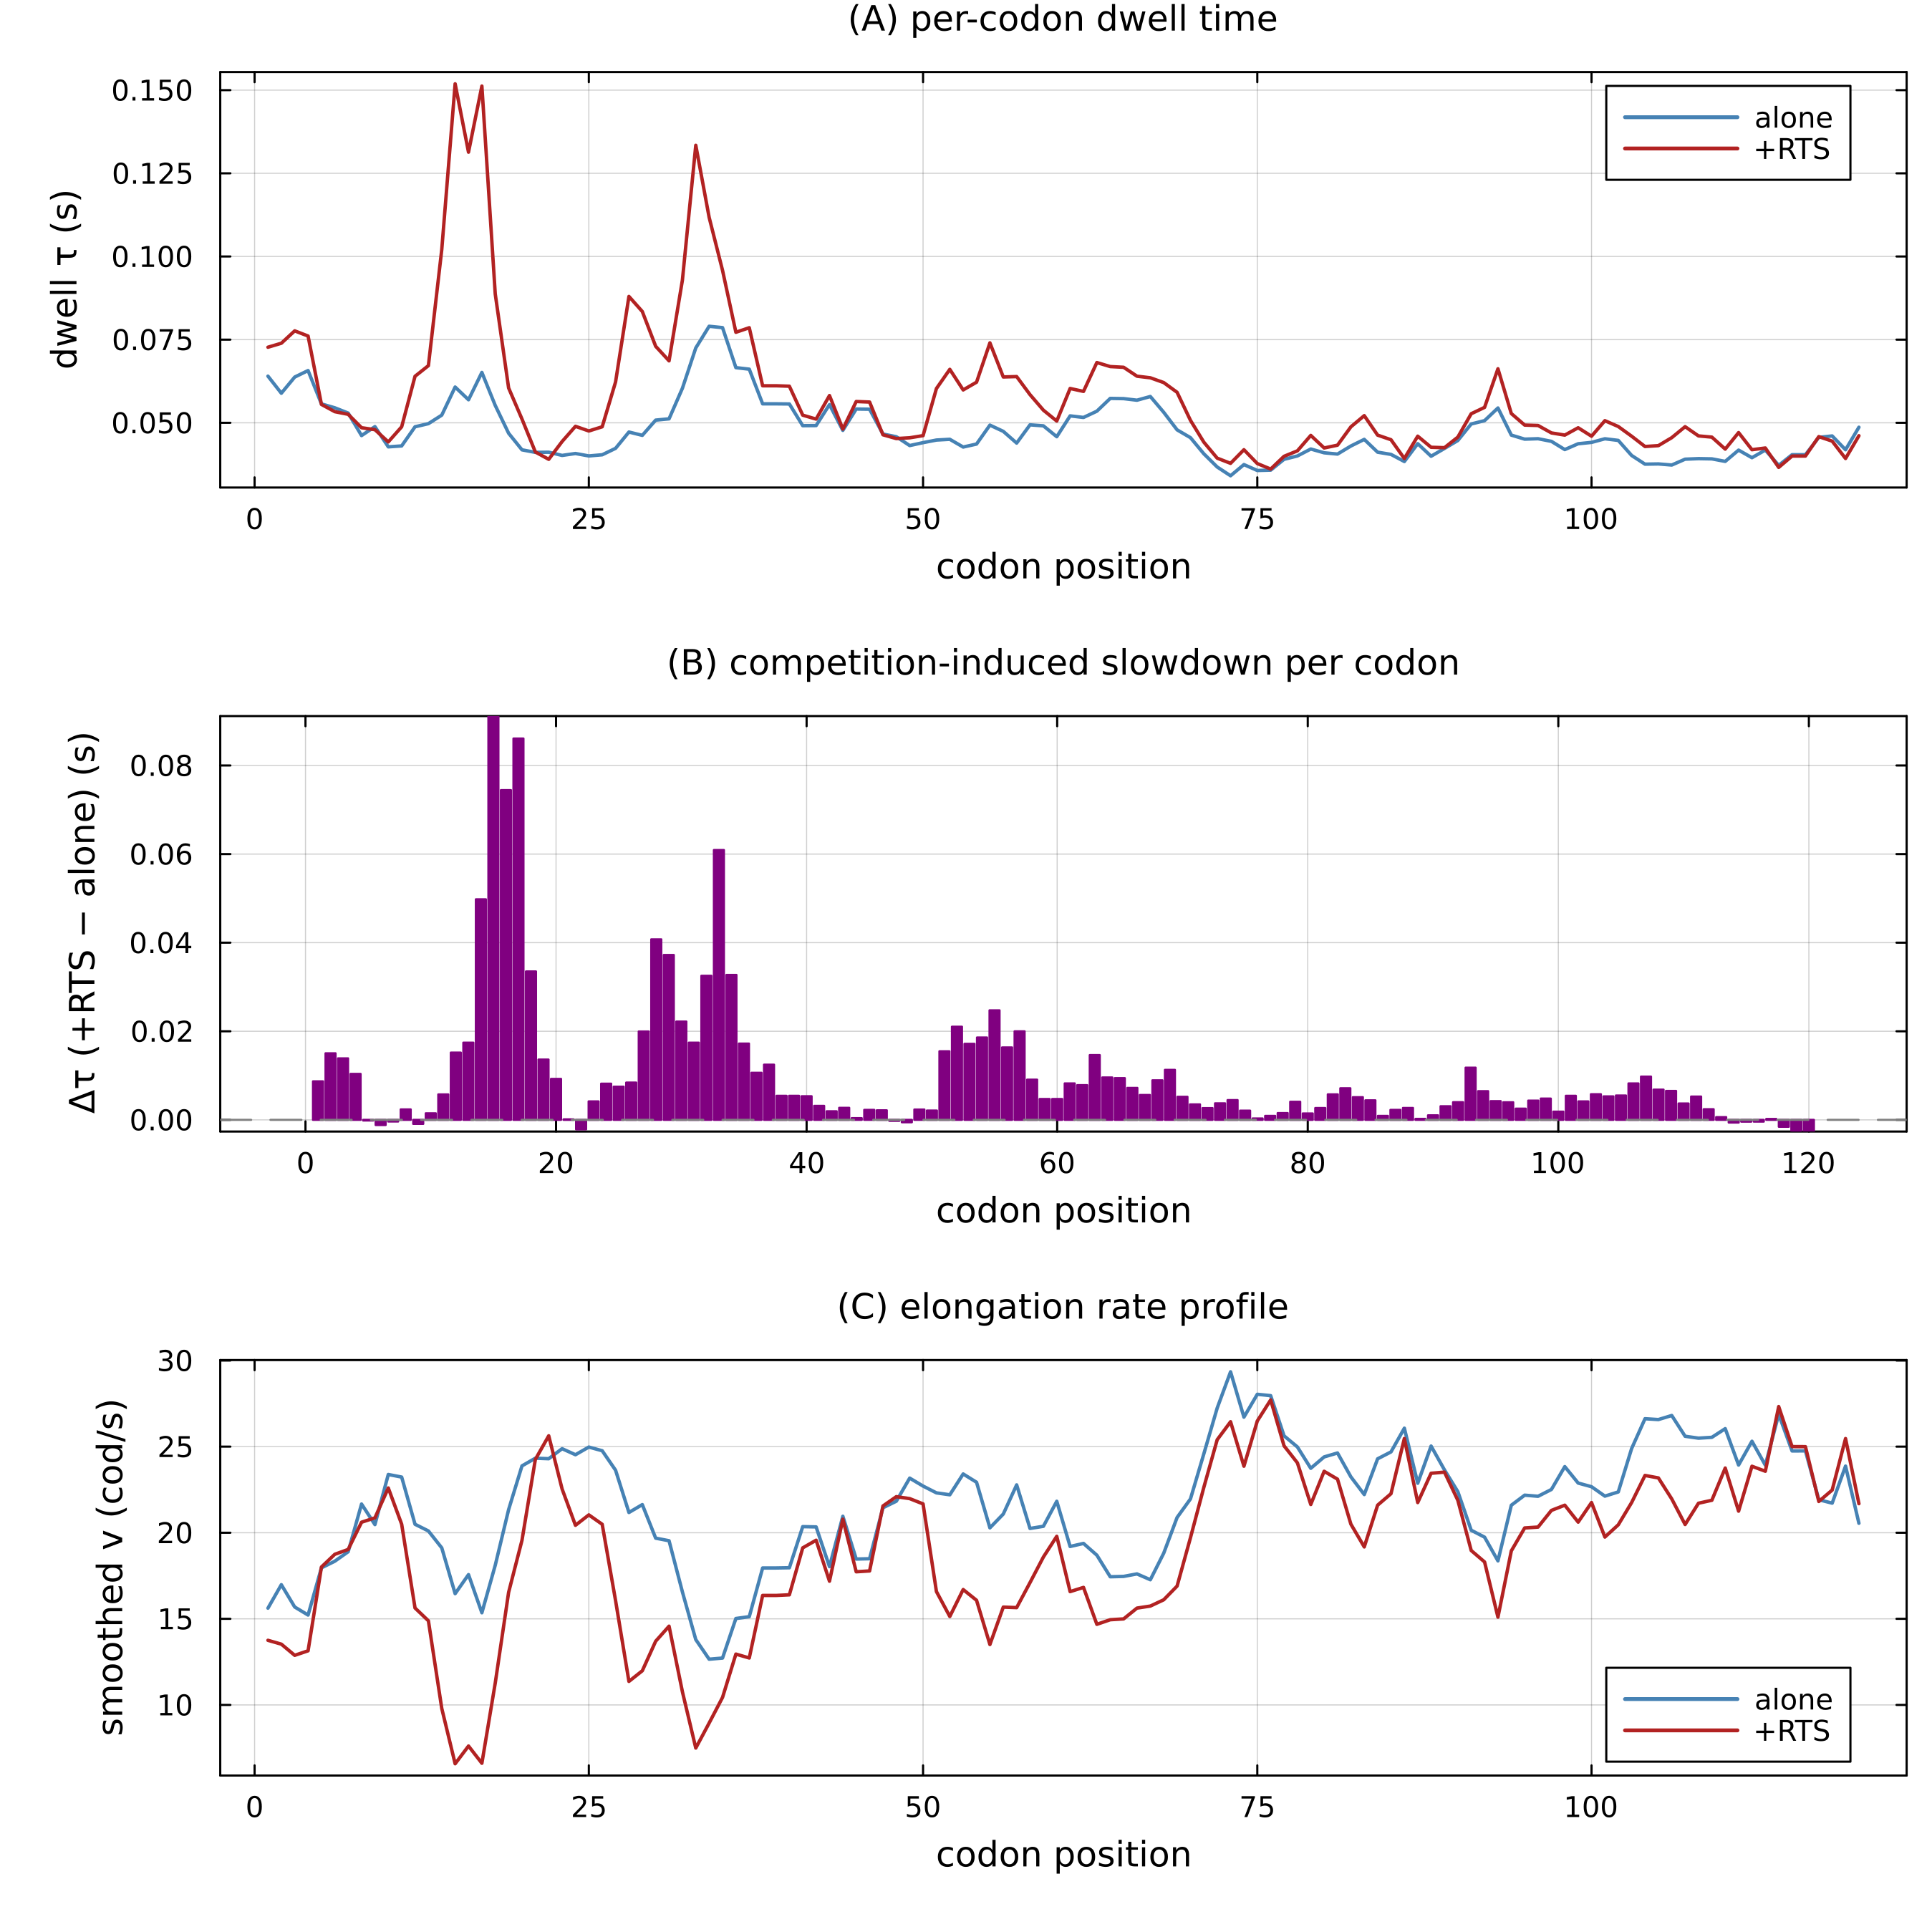

In [3]:
# ════════════════════════════════════════════════════════════════════════════
#  Spindler-faithful rplL comparison: WITHOUT RTS (alone) vs WITH RTS (+3 eCU).
#  Paper (ACS Synth. Biol. 2025, 10.1021/acssynbio.4c00578) predicts the rplL
#  translation time is ~8% LONGER when it competes with the reference
#  transcriptome (shared T3 / tRNA / EF pool depletion).
#  Driver for spindler_rts_comparison() (functions.jl 2751-2912).
# ════════════════════════════════════════════════════════════════════════════

T_SAMPLE = 100.0   # min — elongation snapshot time (paper default)

res = spindler_rts_comparison(
    rplL_seq      = rplL_seq,
    rts_seqs      = rts_seqs,
    growth_rate   = 1,         # µ = 1 h⁻¹ (paper)
    m_rplL_alone  = 0.001,     # MAIN_single_sequence.m, V_TC_scale=1 → ss≈0.001 µM
    m_rplL_rts    = 0.46,      # +RTS case, V_TC_scale=340 → ss≈0.46 µM
    m_rts_each    = 0.31,      # each eCU, V_TC_scale=1133 → ss≈0.31 µM
    t_sample      = T_SAMPLE,
    ode_reltol    = 1e-8,
    ode_abstol    = 1e-6,
    ode_maxiters  = 5_000_000,
    static_EFs    = true,
    spindler_75pct = true,
)

a, b = res.sp_alone, res.sp_rts

# ── Summary ──────────────────────────────────────────────────────────────────
println("\n", "═"^70)
@printf("rplL elongation @ t=%.0f min   (L = %d codons)\n", res.t_sample, a.L)
println("─"^70)
@printf("  WITHOUT RTS:  Στ = %8.3f s   mean v = %6.3f cod/s   RIB = %7.3f µM\n",
        a.total_time_s, a.mean_v, res.rib_alone)
@printf("  WITH    RTS:  Στ = %8.3f s   mean v = %6.3f cod/s   RIB = %7.3f µM\n",
        b.total_time_s, b.mean_v, res.rib_rts)
println("─"^70)
@printf("  Δ(Στ)        = %+.3f s\n", res.delta_total_s)
@printf("  %% longer     = %+.2f %%   (paper prediction ≈ +8 %%)\n", res.pct_longer)
println("─"^70)
println("  Active-ribosome loading per gene (+RTS case):")
let names = vcat(["rplL"], sort(collect(keys(rts_seqs))))
    for (nm, r) in zip(names, res.rib_rts_vec)
        @printf("    %-10s  %7.3f µM\n", nm, r)
    end
end
println("═"^70)

# ── Per-codon CSV ────────────────────────────────────────────────────────────
codons = [SubString(rplL_seq, 3i-2, 3i) for i in 1:a.L]   # codon at each position
detail = DataFrame(
    pos        = 1:a.L,
    codon      = codons,
    tau_alone  = a.tau,
    tau_rts    = b.tau,
    dtau       = res.delta_tau,
    v_alone    = a.v_smooth,
    v_rts      = b.v_smooth,
)
mkpath("../data/output")
CSV.write("../data/output/spindler_rplL_rts_codon_detail.csv", detail)

summary = DataFrame(
    case          = ["alone", "rts"],
    total_time_s  = [a.total_time_s, b.total_time_s],
    mean_v        = [a.mean_v, b.mean_v],
    RIB_active    = [res.rib_alone, res.rib_rts],
    pct_longer    = [0.0, res.pct_longer],
    m_rplL        = [res.m_rplL_alone, res.m_rplL_rts],
)
CSV.write("../data/output/spindler_rplL_rts_summary.csv", summary)
println("Saved → spindler_rplL_rts_{codon_detail,summary}.csv")

# ── Plots ────────────────────────────────────────────────────────────────────
default(fontfamily="sans-serif", framestyle=:box, dpi=300,
        guidefontsize=11, tickfontsize=9, legendfontsize=9, titlefontsize=11)

p1 = plot(1:a.L, a.tau, lw=1.6, c=:steelblue, label="alone",
          xlabel="codon position", ylabel="dwell τ (s)",
          title="(A) per-codon dwell time")
plot!(p1, 1:a.L, b.tau, lw=1.6, c=:firebrick, label="+RTS")

p2 = bar(1:a.L, res.delta_tau, c=:purple, lc=:purple, label=false,
         xlabel="codon position", ylabel="Δτ (+RTS − alone) (s)",
         title="(B) competition-induced slowdown per codon")
hline!(p2, [0.0], c=:gray, ls=:dash, label=false)

p3 = plot(1:a.L, a.v_smooth, lw=1.6, c=:steelblue, label="alone",
          xlabel="codon position", ylabel="smoothed v (cod/s)",
          title="(C) elongation rate profile")
plot!(p3, 1:a.L, b.v_smooth, lw=1.6, c=:firebrick, label="+RTS")

fig = plot(p1, p2, p3, layout=(3,1), size=(900,900),
           left_margin=6Plots.mm, bottom_margin=4Plots.mm)
mkpath("../data/output/figures")
savefig(fig, "../data/output/figures/spindler_rplL_rts.png")
savefig(fig, "../data/output/figures/spindler_rplL_rts.pdf")
println("Saved → figures/spindler_rplL_rts.{png,pdf}")
display(fig)

In [2]:
# ─── Slowest-codon report from saved per-codon detail ───
using CSV, DataFrames, Printf
detail = CSV.read("../data/output/spindler_rplL_rts_codon_detail.csv", DataFrame)

# slowest codon in each case = argmax of dwell time τ
i_alone = argmax(detail.tau_alone)
i_rts   = argmax(detail.tau_rts)
i_dtau  = argmax(detail.dtau)      # codon most slowed BY competition (+RTS − alone)

@printf("Slowest codon WITHOUT RTS : pos %3d  codon %s  τ = %.4f s  (v = %.3f cod/s)\n",
        detail.pos[i_alone], detail.codon[i_alone], detail.tau_alone[i_alone], detail.v_alone[i_alone])
@printf("Slowest codon WITH    RTS : pos %3d  codon %s  τ = %.4f s  (v = %.3f cod/s)\n",
        detail.pos[i_rts],   detail.codon[i_rts],   detail.tau_rts[i_rts],   detail.v_rts[i_rts])
@printf("Most competition-slowed   : pos %3d  codon %s  Δτ = %+.4f s\n",
        detail.pos[i_dtau],  detail.codon[i_dtau],  detail.dtau[i_dtau])

println("\nTop 10 slowest codons (+RTS):")
top = sort(detail, :tau_rts, rev=true)[1:min(10,nrow(detail)), [:pos,:codon,:tau_alone,:tau_rts,:dtau]]
show(top, allrows=true, allcols=true); println()

Slowest codon WITHOUT RTS : pos  34  codon TCC  τ = 0.0790 s  (v = 12.656 cod/s)
Slowest codon WITH    RTS : pos  15  codon ATG  τ = 0.1519 s  (v = 6.583 cod/s)
Most competition-slowed   : pos  15  codon ATG  Δτ = +0.0912 s

Top 10 slowest codons (+RTS):
10×5 DataFrame
 Row │ pos    codon    tau_alone  tau_rts    dtau      
     │ Int64  String3  Float64    Float64    Float64   
─────┼─────────────────────────────────────────────────
   1 │    15  ATG      0.0607476  0.151901   0.0911532
   2 │    17  GTA      0.0651377  0.151222   0.0860845
   3 │    33  GTT      0.0724984  0.133412   0.0609136
   4 │    16  TCT      0.0569237  0.131357   0.0744336
   5 │    34  TCC      0.0790167  0.111741   0.032724
   6 │    14  GCT      0.0523013  0.10209    0.0497888
   7 │    35  GCT      0.0786055  0.0958354  0.0172299
   8 │    32  GGT      0.0603822  0.0929058  0.0325237
   9 │    18  ATG      0.0552139  0.0887181  0.0335042
  10 │    28  GAA      0.0472236  0.0879787  0.0407551
